# Analisis Bab IV — Pengelompokan Citra Sampah Elektronik Berbasis CLIP ViT-H/14 dengan Algoritma K-Means++

Notebook ini adalah versi kode dan output dari **Bab IV Hasil dan Pembahasan**. 

| Item | Keterangan |
|------|------------|
| **Judul skripsi** | Pengelompokan Citra Sampah Elektronik Berbasis CLIP ViT-H/14 dengan Algoritma K-Means++ |
| **Dataset** | `samuelfrans/bdc2026-dataset`, folder `1_Electronic` (3.961 citra) |
| **Data penelitian** | 2.660 citra dari 10 kategori perangkat (hasil filterisasi nama file) |
| **Ekstraksi fitur** | CLIP ViT-H/14, bobot `laion2b_s32b_b79k` (open_clip) |
| **Alur analisis** | Embedding 1.024 dimensi → normalisasi L2 → UMAP 50 dimensi → K-Means++ (K dipilih dengan Silhouette Score) → bootstrap ARI → pelabelan cluster dengan CLIP zero-shot → evaluasi eksternal |
| **Lingkungan** | Kaggle, GPU NVIDIA Tesla T4, `SEED = 42` |

## Daftar Isi
0. [Persiapan Lingkungan dan Data](#s0)
1. [4.1 Statistika Deskriptif](#s41)
2. [4.2 Filterisasi Data](#s42)
3. [4.3 Ekstraksi Fitur Citra](#s43)
   - 4.3.1 Persiapan Citra sebagai Input CLIP · 4.3.2 Konfigurasi CLIP ViT-H/14 · 4.3.3 Pemrosesan Citra dalam Batch · 4.3.4 Ekstraksi Fitur melalui Image Encoder · 4.3.5 Penyusunan Hasil Embedding
4. [4.4 Normalisasi L2](#s44)
5. [4.5 Reduksi Dimensi menggunakan UMAP](#s45)
6. [4.6 Proses dan Hasil Clustering dengan K-Means++](#s46)
7. [4.7 Bootstrap](#s47)
8. [4.8 Pelabelan Cluster menggunakan CLIP Zero-Shot](#s48)
9. [4.9 Metrik Evaluasi Eksternal](#s49)
10. [4.10 Analisis Hasil Cluster](#s410)
11. [Ringkasan dan Pencocokan dengan Naskah](#sr)

---

## 0. Persiapan Lingkungan dan Data <a id='s0'></a>

### 0.1 Instalasi paket
Versi `open_clip_torch` dan `umap-learn` dikunci sama dengan run yang dipakai di naskah, agar angka yang dihasilkan dapat direproduksi.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'open_clip_torch==3.3.0', 'umap-learn==0.5.12'], check=False)
print('Instalasi selesai')

Instalasi selesai


### 0.2 Import pustaka dan konfigurasi
Seluruh parameter analisis dikumpulkan di satu sel agar mudah diperiksa.

In [2]:
# ── Pustaka standar ─────────────────────────────────────────────
import os, re, json, time, random, warnings, platform
from pathlib import Path
from collections import Counter
warnings.filterwarnings('ignore')

# ── Data dan visualisasi ────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from IPython.display import display

# ── Model dan analisis ──────────────────────────────────────────
import torch, open_clip, umap, sklearn
from sklearn.cluster import KMeans, kmeans_plusplus
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, normalized_mutual_info_score)

# ── Konfigurasi analisis ────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CLIP_MODEL, CLIP_PRETRAIN = 'ViT-H-14', 'laion2b_s32b_b79k'
BATCH_SIZE = 64
TARGET_CLASSES = ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse',
                  'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']
K_RANGE = list(range(2, 26))        # kandidat jumlah cluster
N_BOOT = 50                         # jumlah pengulangan bootstrap
SAMPLE_FILE = 'Keyboard_0.jpg'      # citra sampel untuk perhitungan manual
VALID_EXT = {'.jpg', '.jpeg', '.png', '.gif', '.webp', '.bmp'}
OUT = Path('/kaggle/working/hasil_notebook') if Path('/kaggle').exists() else Path('hasil_notebook')
OUT.mkdir(parents=True, exist_ok=True)

# ── Gaya grafik ─────────────────────────────────────────────────
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
PAL = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
       '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
COL = dict(zip(TARGET_CLASSES, PAL))
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

# ── Fungsi bantu tampilan ───────────────────────────────────────
def judul(teks):
    print('=' * 72); print(' ', teks); print('=' * 72)

def ringkas(v, n=3, d=4):
    """Tampilkan n elemen pertama dan n elemen terakhir sebuah vektor."""
    v = np.asarray(v, dtype=float).ravel()
    f = lambda a: ', '.join(f'{x:.{d}f}' for x in a)
    return f'[{f(v[:n])}, …, {f(v[-n:])}]  (panjang {v.size})'

env = {'Python': platform.python_version(), 'PyTorch': torch.__version__,
       'open_clip': open_clip.__version__, 'umap-learn': umap.__version__,
       'scikit-learn': sklearn.__version__, 'NumPy': np.__version__,
       'Perangkat': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}
display(pd.DataFrame(env.items(), columns=['Komponen', 'Versi']))

,Komponen,Versi
0,Python,3.13.16
1,PyTorch,2.11.0+cu130
2,open_clip,3.3.0
3,umap-learn,0.5.12
4,scikit-learn,1.6.1
5,NumPy,2.1.3
6,Perangkat,Tesla T4


### 0.3 Memuat daftar file citra
Seluruh file citra pada folder `1_Electronic` dibaca, lalu setiap nama file diberi label kategori berdasarkan prefiksnya. Aturan pemberian label dijelaskan pada subbab 4.2.

In [3]:
DATASET_DIR = next(Path('/kaggle/input').rglob('1_Electronic'))
print('Folder dataset :', DATASET_DIR)

def get_class(fname):
    """Normalisasi nama file lalu cocokkan prefiksnya dengan nama kategori."""
    norm = re.sub(r'[_\-]+', ' ', fname).lower()
    for c in TARGET_CLASSES:
        if norm.startswith(c.lower()):
            return c
    return None

all_paths = sorted(p for p in DATASET_DIR.iterdir() if p.suffix.lower() in VALID_EXT)
df_all = pd.DataFrame({'filename': [p.name for p in all_paths]})
df_all['label'] = df_all['filename'].map(get_class)
df_input = df_all[df_all['label'].notna()].reset_index(drop=True)
df_drop = df_all[df_all['label'].isna()].reset_index(drop=True)
input_paths = [DATASET_DIR / f for f in df_input['filename']]

print(f'Seluruh citra        : {len(df_all):,}')
print(f'Citra berlabel       : {len(df_input):,}')
print(f'Citra tidak berlabel : {len(df_drop):,}')

Folder dataset : /kaggle/input/datasets/samuelfrans/bdc2026-dataset/train/1_Electronic
Seluruh citra        : 3,961
Citra berlabel       : 2,660
Citra tidak berlabel : 1,301


---
## 4.1 Statistika Deskriptif <a id='s41'></a>

Statistika deskriptif dihitung pada **2.660 citra hasil filterisasi**. Setiap citra RGB berisi tiga kanal intensitas (merah, hijau, biru) bernilai 0–255. Rata-rata dan simpangan baku setiap kanal dihitung dari seluruh piksel pada satu kategori:

$$\bar{x}_c=\frac{1}{N}\sum_{n=1}^{N} x_{n,c}, \qquad s_c=\sqrt{\frac{1}{N}\sum_{n=1}^{N}\left(x_{n,c}-\bar{x}_c\right)^2}$$

dengan $x_{n,c}$ adalah intensitas piksel ke-$n$ pada kanal $c$ dan $N$ adalah jumlah seluruh piksel pada kategori tersebut. Median dihitung secara eksak dari histogram intensitas.

,Kategori,Jumlah Citra,Persentase (%)
0,Battery,220,8.27
1,Keyboard,258,9.70
2,Microwave,259,9.74
3,Mobile,291,10.94
4,Mouse,265,9.96
5,PCB,230,8.65
6,Player,258,9.70
7,Printer,279,10.49
8,Television,300,11.28
9,Washing Machine,300,11.28


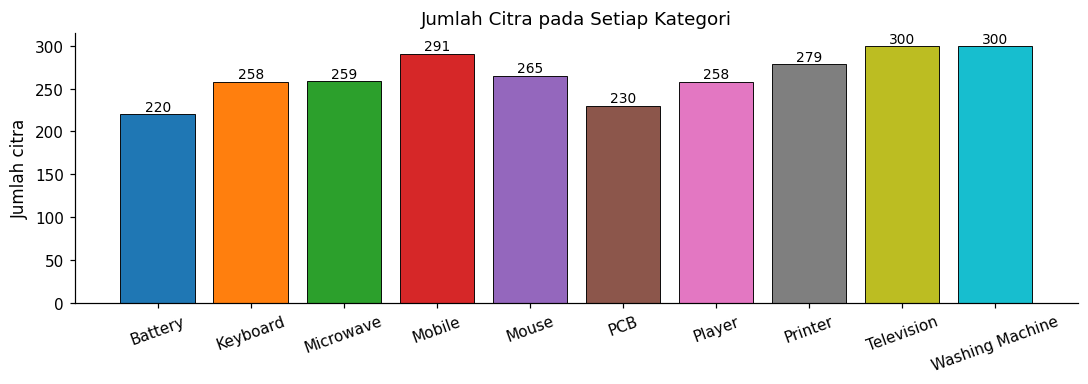

In [4]:
# ── Jumlah citra per kategori ──────────────────────────────────
cnt = df_input['label'].value_counts().reindex(TARGET_CLASSES)
tab_cnt = pd.DataFrame({'Kategori': TARGET_CLASSES, 'Jumlah Citra': cnt.values,
                        'Persentase (%)': (cnt.values / cnt.sum() * 100).round(2)})
tab_cnt.loc[len(tab_cnt)] = ['Total', cnt.sum(), 100.0]
display(tab_cnt)

fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.bar(TARGET_CLASSES, cnt.values, color=PAL, edgecolor='black', lw=0.6)
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, f'{v}', ha='center', fontsize=9)
ax.set_ylabel('Jumlah citra'); ax.set_title('Jumlah Citra pada Setiap Kategori')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [5]:
# ── Format, mode warna, dan ukuran citra ───────────────────────
rows = []
for p in input_paths:
    with Image.open(p) as im:
        rows.append({'filename': p.name, 'format': im.format, 'mode': im.mode,
                     'ukuran': f'{im.width}×{im.height}'})
info = pd.DataFrame(rows)
for kol in ['format', 'mode', 'ukuran']:
    print(f'\n{kol.upper()}'); print(info[kol].value_counts().to_string())


FORMAT
format
JPEG    2660

MODE
mode
RGB    2660

UKURAN
ukuran
150×150    2659
344×258       1


In [6]:
# ── Statistik intensitas RGB per kategori (seluruh piksel) ─────
hist_img = np.zeros((len(input_paths), 3, 256), dtype=np.int64)
mean_img = np.zeros((len(input_paths), 4))
for i, p in enumerate(input_paths):
    a = np.asarray(Image.open(p).convert('RGB')).reshape(-1, 3)
    for ch in range(3):
        hist_img[i, ch] = np.bincount(a[:, ch], minlength=256)
    mean_img[i] = [*a.mean(0), a.mean()]

def stat_hist(h):
    """Rata-rata, median, simpangan baku, min, maks dari histogram 0–255."""
    v = np.arange(256); n = h.sum(); m = (h * v).sum() / n
    sd = np.sqrt((h * (v - m) ** 2).sum() / n)
    med = int(np.searchsorted(np.cumsum(h), (n + 1) / 2)); nz = np.nonzero(h)[0]
    return m, med, sd, nz.min(), nz.max()

rows = []
for cls in TARGET_CLASSES + ['Keseluruhan']:
    m = np.ones(len(df_input), bool) if cls == 'Keseluruhan' else (df_input['label'] == cls).to_numpy()
    for ch, nm in enumerate('RGB'):
        mu, med, sd, mn, mx = stat_hist(hist_img[m, ch].sum(0))
        rows.append({'Kategori': cls, 'Kanal': nm, 'Rata-rata': mu, 'Median': med,
                     'Simpangan Baku': sd, 'Min': mn, 'Maks': mx})
tab_rgb = pd.DataFrame(rows)
display(tab_rgb.round(2).set_index(['Kategori', 'Kanal']))

Rata-rata  Median  Simpangan Baku  Min  Maks
Kategori        Kanal                                              
Battery         R         190.89     251           87.52    0   255
                G         189.39     252           87.75    0   255
                B         186.82     251           89.54    0   255
Keyboard        R         136.45     120           93.61    0   255
                G         134.79     115           93.69    0   255
                B         133.25     112           93.60    0   255
Microwave       R         147.26     156           88.57    0   255
                G         144.06     151           89.03    0   255
                B         140.47     144           90.10    0   255
Mobile          R         122.23     125           79.07    0   255
                G         114.73     112           76.08    0   255
                B         111.14     106           74.08    0   255
Mouse           R         151.00     163           85.80    0   255
                G         145.18     150           86.04    0   255
                B         140.70     141           87.71    0   255
PCB             R         123.68     114           81.95    0   255
                G         133.94     129           74.07    0   255
                B         111.94      98           78.44    0   255
Player          R         169.28     196           87.58    0   255
                G         161.31     184           92.10    0   255
                B         157.31     177           94.39    0   255
Printer         R         149.21     150           82.56    0   255
                G         147.37     148           82.85    0   255
                B         144.73     145           84.29    0   255
Television      R         121.18     110           84.62    0   255
                G         120.61     110           84.14    0   255
                B         119.24     105           85.92    0   255
Washing Machine R         181.31     212           79.18    0   255
                G         179.95     211           80.47    0   255
                B         181.82     214           79.84    0   255
Keseluruhan     R         148.70     157           88.09    0   255
                G         146.41     151           87.70    0   255
                B         142.35     143           89.34    0   255

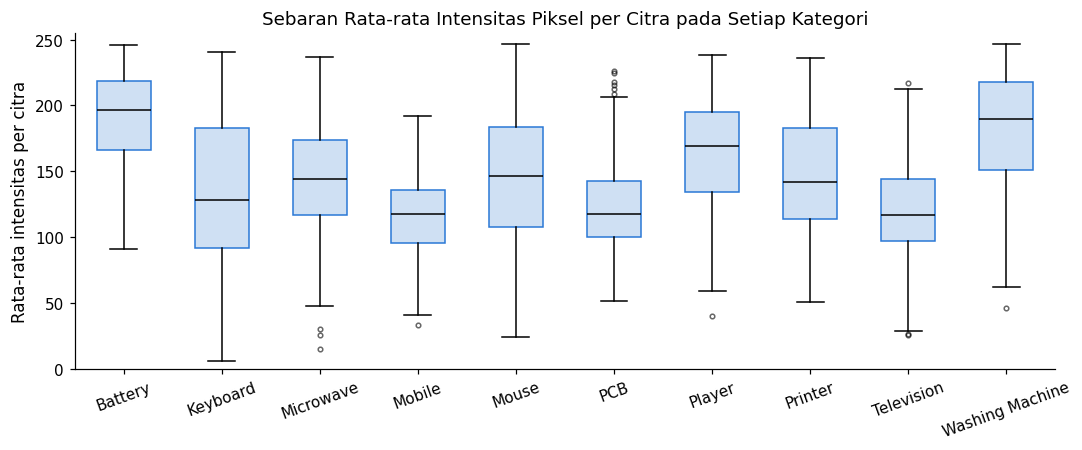

In [7]:
# ── Sebaran rata-rata intensitas per citra ─────────────────────
mi = pd.DataFrame(mean_img, columns=['R', 'G', 'B', 'Semua']).assign(label=df_input['label'])
fig, ax = plt.subplots(figsize=(10, 4.2))
bp = ax.boxplot([mi.loc[mi.label == c, 'Semua'] for c in TARGET_CLASSES], patch_artist=True, widths=0.55,
                medianprops=dict(color='black'), flierprops=dict(marker='o', ms=3, mfc='none', alpha=0.6))
for b in bp['boxes']: b.set(facecolor='#cfe0f3', edgecolor='#2a78d6')
ax.set_xticks(range(1, 11)); ax.set_xticklabels(TARGET_CLASSES, rotation=20)
ax.set_ylabel('Rata-rata intensitas per citra'); ax.set_ylim(0, 255)
ax.set_title('Sebaran Rata-rata Intensitas Piksel per Citra pada Setiap Kategori')
plt.tight_layout(); plt.show()

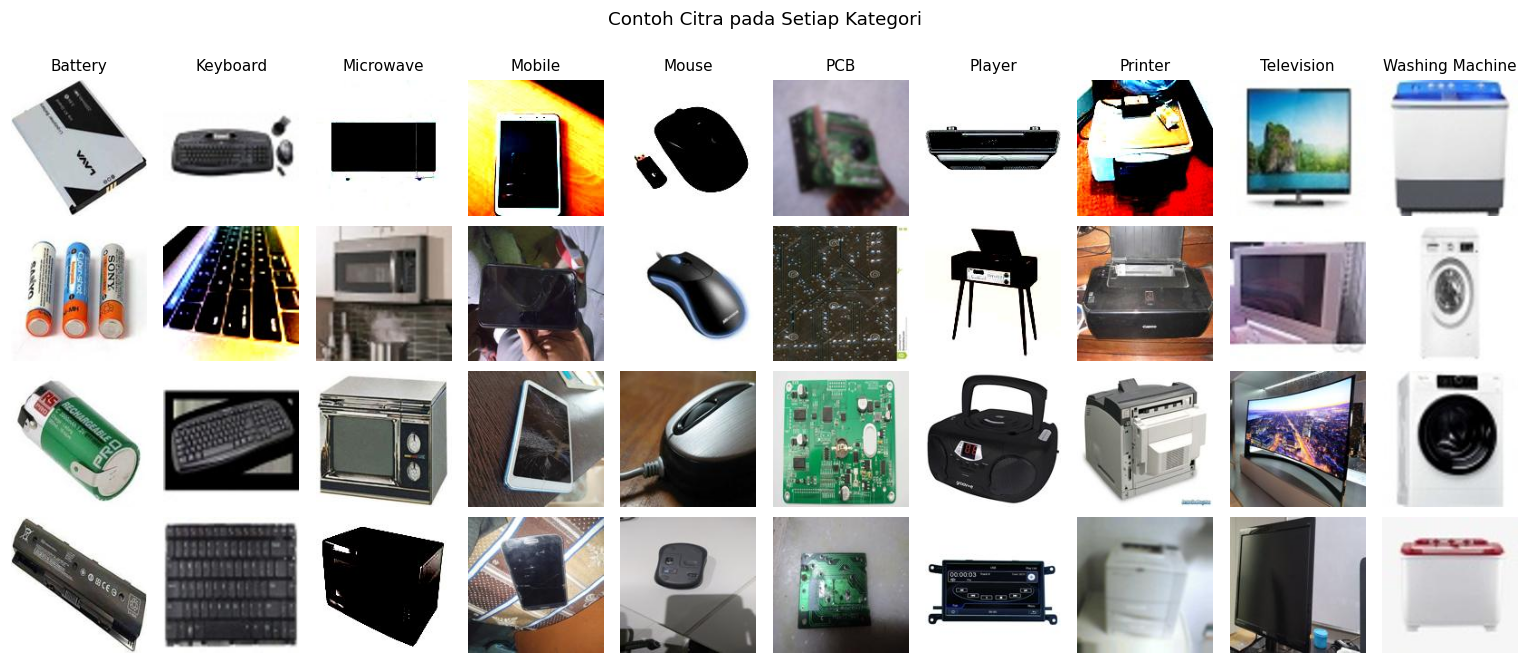

In [8]:
# ── Contoh citra setiap kategori ───────────────────────────────
rng = np.random.RandomState(SEED)
fig, axs = plt.subplots(4, 10, figsize=(14, 6))
for j, c in enumerate(TARGET_CLASSES):
    files = rng.choice(df_input.loc[df_input.label == c, 'filename'], 4, replace=False)
    for i, f in enumerate(files):
        axs[i, j].imshow(Image.open(DATASET_DIR / f).convert('RGB')); axs[i, j].axis('off')
    axs[0, j].set_title(c, fontsize=10)
plt.suptitle('Contoh Citra pada Setiap Kategori', y=1.0); plt.tight_layout(); plt.show()

**Interpretasi.** Nilai minimum dan maksimum setiap kanal pada semua kategori adalah 0 dan 255, artinya setiap kategori memuat piksel yang sepenuhnya gelap dan sepenuhnya terang. Kotak pada diagram boks saling tumpang tindih, terutama Microwave, Mouse, Printer, dan Keyboard. Jadi kategori perangkat **tidak dapat dibedakan hanya dari intensitas warna**. Diperlukan representasi fitur yang menangkap bentuk dan konteks objek, dan itulah peran CLIP pada subbab 4.3.

---
## 4.2 Filterisasi Data <a id='s42'></a>

Filterisasi memilih citra yang nama filenya memuat keterangan kategori. Aturannya:
1. ganti tanda garis bawah (`_`) dan tanda hubung (`-`) dengan spasi;
2. ubah seluruh huruf menjadi huruf kecil;
3. citra digunakan jika nama file yang sudah dinormalisasi **diawali** nama salah satu dari sepuluh kategori.

In [9]:
# ── Contoh penerapan aturan filterisasi ────────────────────────
contoh = [df_input.loc[df_input.label == c, 'filename'].iloc[0] for c in TARGET_CLASSES[:5]]
contoh += list(df_drop['filename'].sample(5, random_state=SEED))
tab_contoh = pd.DataFrame({'Nama file': contoh,
                           'Setelah normalisasi': [re.sub(r'[_\-]+', ' ', f).lower() for f in contoh],
                           'Kategori': [get_class(f) or '—' for f in contoh],
                           'Keputusan': ['Digunakan' if get_class(f) else 'Tidak digunakan' for f in contoh]})
display(tab_contoh)

,Nama file,Setelah normalisasi,Kategori,Keputusan
0,battery_0.jpg,battery 0.jpg,Battery,Digunakan
1,Keyboard_0.jpg,keyboard 0.jpg,Keyboard,Digunakan
2,Microwave_0.jpg,microwave 0.jpg,Microwave,Digunakan
3,Mobile_0.jpg,mobile 0.jpg,Mobile,Digunakan
4,Mouse_10.jpg,mouse 10.jpg,Mouse,Digunakan
5,4.WHY-ARE-ELECTRONICS-BECOMING-OBSOLETE-FASTER...,4.why are electronics becoming obsolete faster...,—,Tidak digunakan
6,612.jpeg,612.jpeg,—,Tidak digunakan
7,217.jpeg,217.jpeg,—,Tidak digunakan
8,587.jpeg,587.jpeg,—,Tidak digunakan
9,79.6.jpg,79.6.jpg,—,Tidak digunakan


In [10]:
# ── Hasil filterisasi ──────────────────────────────────────────
n_all = len(df_all)
tab_filter = pd.DataFrame({'Keterangan': ['Digunakan', 'Tidak digunakan', 'Total'],
                           'Jumlah Citra': [len(df_input), len(df_drop), n_all],
                           'Persentase (%)': [len(df_input) / n_all * 100, len(df_drop) / n_all * 100, 100]}).round(2)
display(tab_filter)

def prefix(f):
    s = re.sub(r'\d+', ' ', Path(f).stem.lower())
    s = re.sub(r'[_\-\.\(\)\s]+', ' ', s).strip()
    return ' '.join(s.split()[:2]) if s else '(angka saja)'
print('Prefiks terbanyak pada citra yang tidak digunakan:')
display(df_drop['filename'].map(prefix).value_counts().head(8).rename_axis('Prefiks').reset_index(name='Jumlah'))

,Keterangan,Jumlah Citra,Persentase (%)
0,Digunakan,2660,67.15
1,Tidak digunakan,1301,32.85
2,Total,3961,100.00


Prefiks terbanyak pada citra yang tidak digunakan:


,Prefiks,Jumlah
0,(angka saja),463
1,img,77
2,copy of,51
3,img wa,38
4,whatsapp image,30
5,e waste,23
6,depositphotos stock,13
7,electronic waste,12


**Interpretasi.** Sebanyak 2.660 citra (67,15%) memenuhi aturan dan menjadi data penelitian, sedangkan 1.301 citra (32,85%) tidak digunakan. Citra yang dibuang umumnya bernama nomor urut, nama bawaan kamera atau WhatsApp, atau istilah umum seperti "e waste", sehingga jenis perangkatnya tidak dapat dipastikan.

---
## 4.3 Ekstraksi Fitur Citra <a id='s43'></a>

Fitur citra diekstraksi dengan *image encoder* CLIP ViT-H/14. Model dipakai apa adanya, **tanpa pelatihan ulang**, sehingga seluruh bobotnya tetap.

In [11]:
t0 = time.time()
model, _, preprocess = open_clip.create_model_and_transforms(CLIP_MODEL, pretrained=CLIP_PRETRAIN, device=DEVICE)
model.eval()
tokenizer = open_clip.get_tokenizer(CLIP_MODEL)
V = model.visual
print(f'Model {CLIP_MODEL} ({CLIP_PRETRAIN}) dimuat dalam {time.time() - t0:.1f} detik di {DEVICE}')
print(preprocess)

Model ViT-H-14 (laion2b_s32b_b79k) dimuat dalam 34.4 detik di cuda
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


### 4.3.1 Persiapan Citra sebagai Input CLIP
Setiap citra melewati lima tahap *preprocessing* bawaan model: *resize* (sisi terpendek menjadi 224 piksel, interpolasi bicubic), *center crop* 224×224, pemastian mode RGB, konversi menjadi tensor (dibagi 255), dan normalisasi per kanal:

$$x'_c(i,j)=\frac{I_c(i,j)/255-\mu_c}{\sigma_c}$$

dengan $\mu_c$ dan $\sigma_c$ adalah rata-rata dan simpangan baku kanal $c$ pada data pelatihan CLIP.

,Tahap,Tipe,Ukuran,Nilai min,Nilai maks
0,Asli,PIL Image,150×150×3,0.0000,255.0000
1,Resize,PIL Image,224×224×3,0.0000,255.0000
2,CenterCrop,PIL Image,224×224×3,0.0000,255.0000
3,MaybeConvertMode,PIL Image,224×224×3,0.0000,255.0000
4,MaybeToTensor,Tensor,3×224×224,0.0000,1.0000
5,Normalize,Tensor,3×224×224,-1.7923,2.1459


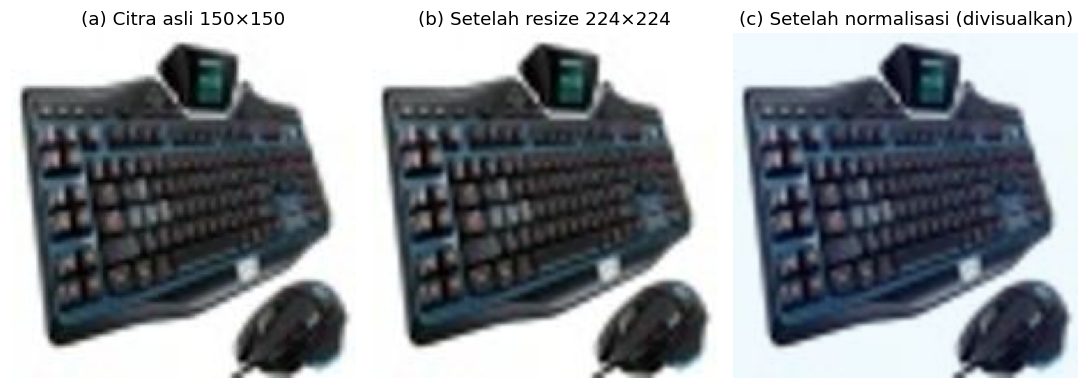

In [12]:
img = Image.open(DATASET_DIR / SAMPLE_FILE).convert('RGB')
x, stages, rows = img, {'Asli': img}, []
for t in preprocess.transforms:
    x = t(x); stages[type(t).__name__] = x
for nm, v in stages.items():
    if isinstance(v, Image.Image):
        a = np.asarray(v); rows.append([nm, 'PIL Image', f'{v.width}×{v.height}×3', a.min(), a.max()])
    else:
        rows.append([nm, 'Tensor', '×'.join(map(str, v.shape)), round(v.min().item(), 4), round(v.max().item(), 4)])
display(pd.DataFrame(rows, columns=['Tahap', 'Tipe', 'Ukuran', 'Nilai min', 'Nilai maks']))

arr_crop = np.asarray(stages['CenterCrop']); x_norm = stages['Normalize']
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))
axs[0].imshow(img); axs[0].set_title(f'(a) Citra asli {img.width}×{img.height}')
axs[1].imshow(np.asarray(stages['Resize'])); axs[1].set_title('(b) Setelah resize 224×224')
vis = x_norm.numpy().transpose(1, 2, 0); vis = (vis - vis.min()) / (vis.max() - vis.min())
axs[2].imshow(vis); axs[2].set_title('(c) Setelah normalisasi (divisualkan)')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()

In [13]:
# ── Perhitungan manual normalisasi pada piksel (112, 112) ──────
norm_t = [t for t in preprocess.transforms if type(t).__name__ == 'Normalize'][0]
MEAN, STD = np.array(norm_t.mean), np.array(norm_t.std)
judul(f'Normalisasi piksel baris 112, kolom 112 pada {SAMPLE_FILE}')
for c, nm in enumerate('RGB'):
    I = int(arr_crop[112, 112, c])
    manual = (I / 255 - MEAN[c]) / STD[c]
    print(f"Kanal {nm}: x' = ({I}/255 − {MEAN[c]:.4f}) / {STD[c]:.4f} = {manual:.4f}"
          f"   | tensor open_clip = {x_norm[c, 112, 112].item():.4f}")
print('\nPiksel putih (255) setelah normalisasi:',
      ', '.join(f'{nm} = {(1 - MEAN[c]) / STD[c]:.4f}' for c, nm in enumerate('RGB')))
print('\nPotongan tensor kanal R di sekitar pusat citra (baris/kolom 110–114):')
display(pd.DataFrame(x_norm[0, 110:115, 110:115].numpy().round(4),
                     index=range(110, 115), columns=range(110, 115)))

  Normalisasi piksel baris 112, kolom 112 pada Keyboard_0.jpg
Kanal R: x' = (47/255 − 0.4815) / 0.2686 = -1.1061   | tensor open_clip = -1.1061
Kanal G: x' = (47/255 − 0.4578) / 0.2613 = -1.0467   | tensor open_clip = -1.0467
Kanal B: x' = (47/255 − 0.4082) / 0.2758 = -0.8119   | tensor open_clip = -0.8119

Piksel putih (255) setelah normalisasi: R = 1.9303, G = 2.0749, B = 2.1459

Potongan tensor kanal R di sekitar pusat citra (baris/kolom 110–114):


,110,111,112,113,114
110,-0.9456,-1.0185,-1.0915,-1.0915,-1.0185
111,-0.7996,-0.9164,-1.0769,-1.1207,-1.0477
112,-0.7412,-0.8726,-1.1061,-1.1791,-1.1207
113,-0.6974,-0.8726,-1.1353,-1.2229,-1.1791
114,-0.6974,-0.8726,-1.1499,-1.2521,-1.2229


### 4.3.2 Konfigurasi CLIP ViT-H/14
Citra 224×224 dibagi menjadi patch 14×14 piksel tanpa tumpang tindih, sehingga terbentuk $(224/14)^2 = 16^2 = 256$ patch.

,Komponen,Nilai
0,Ukuran citra masukan,224×224 piksel
1,Ukuran patch,14×14 piksel
2,Jumlah patch,256
3,Dimensi token (width),1280
4,Jumlah blok transformer,32
5,Jumlah attention head,16
6,Dimensi MLP,5120
7,Dimensi embedding keluaran,1024
8,Parameter image encoder,"632,076,800"
9,Parameter seluruh model CLIP,"986,109,441"


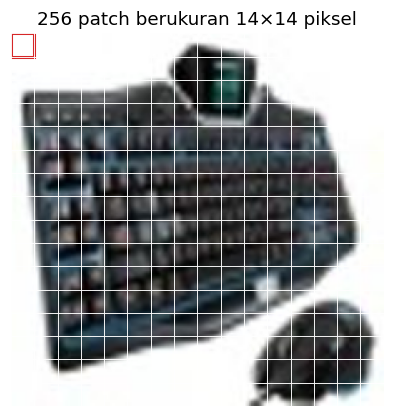

In [14]:
cfg = open_clip.get_model_config(CLIP_MODEL); vc = cfg['vision_cfg']
n_vis = sum(p.numel() for p in V.parameters()); n_all_p = sum(p.numel() for p in model.parameters())
tab_cfg = pd.DataFrame([
    ('Ukuran citra masukan', f"{vc['image_size']}×{vc['image_size']} piksel"),
    ('Ukuran patch', f"{vc['patch_size']}×{vc['patch_size']} piksel"),
    ('Jumlah patch', (vc['image_size'] // vc['patch_size']) ** 2),
    ('Dimensi token (width)', vc['width']),
    ('Jumlah blok transformer', vc['layers']),
    ('Jumlah attention head', vc['width'] // vc['head_width']),
    ('Dimensi MLP', int(vc['width'] * vc.get('mlp_ratio', 4.0))),
    ('Dimensi embedding keluaran', cfg['embed_dim']),
    ('Parameter image encoder', f'{n_vis:,}'),
    ('Parameter seluruh model CLIP', f'{n_all_p:,}')], columns=['Komponen', 'Nilai'])
display(tab_cfg)

fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.imshow(arr_crop)
for k in range(0, 225, 14):
    ax.axhline(k - 0.5, color='white', lw=0.6); ax.axvline(k - 0.5, color='white', lw=0.6)
ax.add_patch(plt.Rectangle((-0.5, -0.5), 14, 14, fill=False, ec='#d62728', lw=2))
ax.set_title('256 patch berukuran 14×14 piksel'); ax.axis('off'); plt.show()

In [15]:
# ── Jumlah parameter per komponen image encoder ────────────────
pv = pd.DataFrame([(n, '×'.join(map(str, p.shape)), p.numel()) for n, p in V.named_parameters()],
                  columns=['param', 'shape', 'numel'])
grp = lambda n: 'transformer.resblocks (32 blok)' if n.startswith('transformer.resblocks.') else n.split('.')[0]
tab_par = pv.assign(Komponen=pv['param'].map(grp)).groupby('Komponen', sort=False)['numel'].sum().reset_index()
tab_par.loc[len(tab_par)] = ['Total', tab_par['numel'].sum()]
display(tab_par.rename(columns={'numel': 'Jumlah Parameter'}))

judul('Perhitungan manual jumlah parameter')
W = V.conv1.weight
print(f'conv1 (patch embedding) : {W.shape[0]} × {W.shape[1]} × {W.shape[2]} × {W.shape[3]} = {W.numel():,}  (bias: {V.conv1.bias is not None})')
blk0 = pv[pv['param'].str.startswith('transformer.resblocks.0.')]
display(blk0.assign(param=blk0['param'].str.replace('transformer.resblocks.0.', '', regex=False)).reset_index(drop=True))
nb0 = blk0['numel'].sum()
print(f'Satu blok transformer   : {nb0:,}')
print(f'32 blok transformer     : 32 × {nb0:,} = {32 * nb0:,}')
print(f'Proyeksi keluaran (proj): {V.proj.shape[0]} × {V.proj.shape[1]} = {V.proj.numel():,}')

,Komponen,Jumlah Parameter
0,class_embedding,1280
1,positional_embedding,328960
2,proj,1310720
3,conv1,752640
4,ln_pre,2560
5,transformer.resblocks (32 blok),629678080
6,ln_post,2560
7,Total,632076800


  Perhitungan manual jumlah parameter
conv1 (patch embedding) : 1280 × 3 × 14 × 14 = 752,640  (bias: False)


,param,shape,numel
0,ln_1.weight,1280,1280
1,ln_1.bias,1280,1280
2,attn.in_proj_weight,3840×1280,4915200
3,attn.in_proj_bias,3840,3840
4,attn.out_proj.weight,1280×1280,1638400
5,attn.out_proj.bias,1280,1280
6,ln_2.weight,1280,1280
7,ln_2.bias,1280,1280
8,mlp.c_fc.weight,5120×1280,6553600
9,mlp.c_fc.bias,5120,5120


Satu blok transformer   : 19,677,440
32 blok transformer     : 32 × 19,677,440 = 629,678,080
Proyeksi keluaran (proj): 1280 × 1024 = 1,310,720


### 4.3.3 Pemrosesan Citra dalam Batch
Citra diproses dalam batch berisi 64 citra. Jumlah batch adalah $\lceil 2.660/64 \rceil = 42$: sebanyak 41 batch berisi 64 citra dan batch terakhir berisi $2.660 - 41\times 64 = 36$ citra.

In [16]:
emb_raw, valid_names, batch_log = [], [], []
t_all = time.time()
for b, i in enumerate(range(0, len(input_paths), BATCH_SIZE)):
    t0 = time.time(); imgs, used = [], []
    for p in input_paths[i:i + BATCH_SIZE]:
        try:
            imgs.append(preprocess(Image.open(p).convert('RGB'))); used.append(p.name)
        except Exception as e:
            print('GAGAL dibaca:', p.name, e)
    xb = torch.stack(imgs).to(DEVICE)
    with torch.no_grad():
        f = model.encode_image(xb)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    emb_raw.append(f.cpu().float().numpy()); valid_names += used
    batch_log.append({'Batch': b + 1, 'Indeks awal': i, 'Indeks akhir': i + len(used) - 1, 'Jumlah citra': len(used),
                      'Ukuran input': '×'.join(map(str, xb.shape)), 'Ukuran output': '×'.join(map(str, f.shape)),
                      'Waktu (detik)': round(time.time() - t0, 2),
                      'Memori GPU maks (MB)': round(torch.cuda.max_memory_allocated() / 2**20, 1) if DEVICE == 'cuda' else 0})
    if (b + 1) % 10 == 0: print(f'  batch {b + 1} selesai')
emb_raw = np.vstack(emb_raw).astype(np.float32)
tab_batch = pd.DataFrame(batch_log)
display(pd.concat([tab_batch.head(3), tab_batch.tail(2)]))
total_t = time.time() - t_all
print(f'Jumlah batch   : {len(tab_batch)}')
print(f'Citra berhasil : {len(valid_names):,} dari {len(input_paths):,}')
print(f'Total waktu    : {total_t:.1f} detik (rata-rata {total_t / len(tab_batch):.2f} detik per batch)')

y_true = df_input.set_index('filename').loc[valid_names, 'label'].to_numpy()
SI = valid_names.index(SAMPLE_FILE)          # indeks citra sampel

  batch 10 selesai
  batch 20 selesai
  batch 30 selesai
  batch 40 selesai


,Batch,Indeks awal,Indeks akhir,Jumlah citra,Ukuran input,Ukuran output,Waktu (detik),Memori GPU maks (MB)
0,1,0,63,64,64×3×224×224,64×1024,9.18,4837.9
1,2,64,127,64,64×3×224×224,64×1024,6.27,4838.1
2,3,128,191,64,64×3×224×224,64×1024,6.43,4838.1
40,41,2560,2623,64,64×3×224×224,64×1024,7.87,4838.1
41,42,2624,2659,36,36×3×224×224,36×1024,4.52,4838.1


Jumlah batch   : 42
Citra berhasil : 2,660 dari 2,660
Total waktu    : 319.6 detik (rata-rata 7.61 detik per batch)


### 4.3.4 Ekstraksi Fitur melalui Image Encoder
Di dalam image encoder, tensor 3×224×224 diubah menjadi vektor 1.024 dimensi melalui lima tahap. Setiap tahap dihitung ulang secara manual pada citra sampel, lalu dicocokkan dengan nilai antara (*intermediate*) yang direkam lewat *forward hook*.

1. **Patch embedding**: konvolusi `conv1` dengan 1.280 filter 3×14×14 dan stride 14:
$$e_f(p,q)=\sum_{c=1}^{3}\sum_{u=1}^{14}\sum_{v=1}^{14} x_c(14p+u,\,14q+v)\,K_{f,c}(u,v)$$
2. **Token kelas dan positional embedding**: $z_0=[x_{\text{class}};\,e_1;\dots;e_{256}]+E_{\text{pos}}$, berukuran 257×1.280.
3. **Layer normalization awal** (`ln_pre`): $\text{LN}(z)=\gamma\odot\dfrac{z-\mu}{\sqrt{\sigma^2+\varepsilon}}+\beta$.
4. **32 blok transformer**, masing-masing berisi *multi-head self-attention* 16 head dan MLP 1.280 → 5.120 → 1.280.
5. **Layer normalization akhir** (`ln_post`) pada token kelas, lalu proyeksi $z = h\,P$ dengan $P$ berukuran 1.280×1.024.

In [17]:
x = preprocess(Image.open(DATASET_DIR / SAMPLE_FILE).convert('RGB')).unsqueeze(0).to(DEVICE)
cap = {}
def hook(nama_in, nama_out):
    def f(m, i, o):
        if nama_in: cap[nama_in] = i[0].detach()
        cap[nama_out] = (o[0] if isinstance(o, tuple) else o).detach()
        return None                    # tidak mengubah keluaran modul
    return f
hooks = [V.conv1.register_forward_hook(hook(None, 'conv1')),
         V.ln_pre.register_forward_hook(hook('ln_pre_in', 'ln_pre_out')),
         V.transformer.register_forward_hook(hook(None, 'tr_out')),
         V.ln_post.register_forward_hook(hook('ln_post_in', 'ln_post_out'))]
with torch.no_grad():
    out = model.encode_image(x)
for h in hooks: h.remove()
tok = lambda t: t.float().cpu()[0] if t.dim() == 3 else t.float().cpu()   # ambil batch pertama

# 1) patch embedding
W1 = V.conv1.weight.detach().float().cpu(); xc = x[0].float().cpu(); P = 14
patch = xc[:, :P, :P]; conv1 = cap['conv1'][0].float().cpu()
judul('1) Patch embedding: filter ke-1 pada patch pojok kiri atas')
print('Nilai piksel patch kanal R (3×3 pertama):\n', patch[0, :3, :3].numpy().round(4))
print('Bobot filter ke-1 kanal R (3×3 pertama):\n', W1[0, 0, :3, :3].numpy().round(4))
pf, wf = patch.flatten(), W1[0].flatten()
suku = ' + '.join(f'({pf[k]:.4f})({wf[k]:.4f})' for k in range(2))
print(f'e_1(0,0) = {suku} + … ({pf.numel()} suku) = {(pf * wf).sum().item():.4f}')
print(f'Nilai dari hook conv1  = {conv1[0, 0, 0].item():.4f}')
print('Ukuran keluaran conv1  :', tuple(conv1.shape), '→ diratakan menjadi', (conv1.shape[1] * conv1.shape[2], conv1.shape[0]))

# 2) token kelas + positional embedding
seq = conv1.reshape(conv1.shape[0], -1).T
cls_e = V.class_embedding.detach().float().cpu(); pos = V.positional_embedding.detach().float().cpu()
z0 = torch.cat([cls_e[None], seq], 0) + pos
lpi = tok(cap['ln_pre_in'])
judul('2) Token kelas + positional embedding (token ke-0)')
print('x_class      :', ringkas(cls_e)); print('E_pos[0]     :', ringkas(pos[0])); print('z_0[0]       :', ringkas(z0[0]))
print(f'Ukuran barisan: {tuple(z0.shape)} | selisih maks terhadap hook = {(z0 - lpi).abs().max().item():.2e}')

# 3) ln_pre
g, bt, eps = V.ln_pre.weight.detach().float().cpu(), V.ln_pre.bias.detach().float().cpu(), V.ln_pre.eps
mu, var = lpi[0].mean().item(), lpi[0].var(unbiased=False).item()
man = (lpi[0, :3] - mu) / np.sqrt(var + eps) * g[:3] + bt[:3]
judul('3) Layer normalization awal pada token kelas')
print(f'μ = {mu:.4f}, σ² = {var:.4f}, ε = {eps}')
print(f'Elemen ke-1: {g[0]:.4f} × ({lpi[0, 0]:.4f} − ({mu:.4f})) / √({var:.4f} + {eps}) + ({bt[0]:.4f}) = {man[0]:.4f}')
print('Manual (3 elemen pertama):', man.numpy().round(4), '| hook:', tok(cap['ln_pre_out'])[0, :3].numpy().round(4))

# 4) blok transformer
judul('4) Keluaran 32 blok transformer')
print('Ukuran:', tuple(cap['tr_out'].shape), '| token kelas:', ringkas(tok(cap['tr_out'])[0]))

# 5) ln_post + proyeksi
hin = tok(cap['ln_post_in']); hin = hin[0] if hin.dim() == 2 else hin
hout = tok(cap['ln_post_out']); h = hout[0] if hout.dim() == 2 else hout
proj = V.proj.detach().float().cpu(); z = h @ proj
judul('5) ln_post dan proyeksi ke 1.024 dimensi')
print(f'ln_post: μ = {hin.mean().item():.4f}, σ² = {hin.var(unbiased=False).item():.4f}')
suku = ' + '.join(f'({h[k]:.4f})({proj[k, 0]:.4f})' for k in range(2))
print(f'z_1 = {suku} + … (1.280 suku) = {z[0].item():.4f}')
print('Vektor embedding manual :', ringkas(z))
print('Keluaran encode_image   :', ringkas(out[0].float().cpu()))
print(f'Selisih absolut maksimum manual vs encode_image : {(z - out[0].float().cpu()).abs().max().item():.7f}')
print(f'Selisih absolut maksimum vs hasil batch (4.3.3) : {np.abs(out[0].float().cpu().numpy() - emb_raw[SI]).max():.7f}')

  1) Patch embedding: filter ke-1 pada patch pojok kiri atas
Nilai piksel patch kanal R (3×3 pertama):
 [[1.9303 1.9303 1.9303]
 [1.9303 1.9303 1.9303]
 [1.9303 1.9303 1.9303]]
Bobot filter ke-1 kanal R (3×3 pertama):
 [[-0.0165 -0.0304 -0.0409]
 [ 0.006  -0.0033 -0.0245]
 [ 0.0105 -0.0007 -0.0256]]
e_1(0,0) = (1.9303)(-0.0165) + (1.9303)(-0.0304) + … (588 suku) = -0.1328
Nilai dari hook conv1  = -0.1328
Ukuran keluaran conv1  : (1280, 16, 16) → diratakan menjadi (256, 1280)
  2) Token kelas + positional embedding (token ke-0)
x_class      : [-0.2058, 0.2923, -0.0113, …, -0.0631, -0.2529, 0.1733]  (panjang 1280)
E_pos[0]     : [-0.0561, 0.0629, -0.0013, …, -0.0278, -0.0584, 0.0596]  (panjang 1280)
z_0[0]       : [-0.2619, 0.3551, -0.0127, …, -0.0909, -0.3113, 0.2329]  (panjang 1280)
Ukuran barisan: (257, 1280) | selisih maks terhadap hook = 0.00e+00
  3) Layer normalization awal pada token kelas
μ = -0.0073, σ² = 0.0414, ε = 1e-05
Elemen ke-1: -0.0010 × (-0.2619 − (-0.0073)) / √(0.0414

**Interpretasi.** Hasil perhitungan manual sama dengan keluaran `encode_image`. Selisihnya hanya berasal dari pembulatan bilangan titik mengambang (orde $10^{-6}$), jadi lima tahap di atas memang menggambarkan apa yang dikerjakan model.

### 4.3.5 Penyusunan Hasil Embedding
Embedding dari seluruh batch digabungkan menjadi matriks fitur $E$ berukuran 2.660×1.024. Urutan barisnya mengikuti urutan nama file.

In [18]:
cols = [f'e{k}' for k in (1, 2, 3)] + ['…'] + [f'e{k}' for k in (1022, 1023, 1024)]
def potong(M, idx):
    d = pd.DataFrame(np.c_[M[idx, :3], np.full(len(idx), np.nan), M[idx, -3:]], columns=cols, index=[valid_names[i] for i in idx])
    return d.round(4).astype(object).where(d.notna(), '…')
display(potong(emb_raw, [0, 1, 2, len(emb_raw) - 2, len(emb_raw) - 1]))
norms = np.linalg.norm(emb_raw, axis=1)
print(f'Ukuran matriks E      : {emb_raw.shape}')
print(f'Rentang nilai elemen  : {emb_raw.min():.4f} sampai {emb_raw.max():.4f}')
print(f'Norma L2 per citra    : min {norms.min():.4f}, rata-rata {norms.mean():.4f}, maks {norms.max():.4f}')

,e1,e2,e3,…,e1022,e1023,e1024
Keyboard_0.jpg,-0.4395,-0.3362,0.3882,…,0.2846,-0.5762,-0.5631
Keyboard_1.jpg,0.1225,0.1112,-0.0934,…,0.3979,-0.0787,0.4328
Keyboard_10.jpg,-0.4373,-0.5076,0.9429,…,-0.2099,0.2814,0.2206
pcb_98.jpg,0.5186,-0.3496,0.5363,…,-0.4185,-0.4687,-0.3127
pcb_99.jpg,0.248,-0.4221,0.6148,…,-0.6406,-0.362,-0.0247


Ukuran matriks E      : (2660, 1024)
Rentang nilai elemen  : -10.8205 sampai 12.4523
Norma L2 per citra    : min 14.7888, rata-rata 21.0613, maks 24.7908


---
## 4.4 Normalisasi L2 <a id='s44'></a>

Normalisasi L2 membuat setiap vektor embedding memiliki panjang satu, sehingga perbandingan antarcitra hanya bergantung pada arah vektor:

$$\lVert \mathbf{e} \rVert_2=\sqrt{\sum_{k=1}^{1024} e_k^2}, \qquad \hat{\mathbf{e}}=\frac{\mathbf{e}}{\lVert \mathbf{e} \rVert_2}$$

In [19]:
emb_l2 = (emb_raw / (norms[:, None] + 1e-12)).astype(np.float32)
v = emb_raw[SI].astype(np.float64); nrm = np.sqrt((v ** 2).sum())
judul(f'Normalisasi L2 citra sampel {SAMPLE_FILE}')
print('Σ e_k² = ' + ' + '.join(f'({v[k]:.4f})²' for k in range(3)) + ' + … + '
      + ' + '.join(f'({v[k]:.4f})²' for k in range(-2, 0)) + f' = {(v ** 2).sum():.4f}')
print(f'‖e‖₂ = √{(v ** 2).sum():.4f} = {nrm:.4f}')
print(f'ê_1    = {v[0]:.4f} / {nrm:.4f} = {v[0] / nrm:.4f}')
print(f'ê_1024 = {v[-1]:.4f} / {nrm:.4f} = {v[-1] / nrm:.4f}')

n_after = np.linalg.norm(emb_l2, axis=1)
tab_norm = pd.DataFrame({'Sebelum normalisasi': pd.Series(norms).describe(),
                         'Sesudah normalisasi': pd.Series(n_after).describe()}).T
display(tab_norm.round(6))
print(f'Rentang elemen setelah normalisasi: {emb_l2.min():.4f} sampai {emb_l2.max():.4f}')
display(potong(emb_l2, [0, 1, 2, len(emb_l2) - 1]))

  Normalisasi L2 citra sampel Keyboard_0.jpg
Σ e_k² = (-0.4395)² + (-0.3362)² + (0.3882)² + … + (-0.5762)² + (-0.5631)² = 462.2763
‖e‖₂ = √462.2763 = 21.5006
ê_1    = -0.4395 / 21.5006 = -0.0204
ê_1024 = -0.5631 / 21.5006 = -0.0262


,count,mean,std,min,25%,50%,75%,max
Sebelum normalisasi,2660.0,21.061308,0.889968,14.788835,20.484851,21.07846,21.65375,24.79077
Sesudah normalisasi,2660.0,1.000000,0.000000,1.000000,1.000000,1.00000,1.00000,1.00000


Rentang elemen setelah normalisasi: -0.4538 sampai 0.5223


,e1,e2,e3,…,e1022,e1023,e1024
Keyboard_0.jpg,-0.0204,-0.0156,0.0181,…,0.0132,-0.0268,-0.0262
Keyboard_1.jpg,0.0058,0.0053,-0.0044,…,0.0189,-0.0037,0.0205
Keyboard_10.jpg,-0.0209,-0.0243,0.0451,…,-0.01,0.0135,0.0106
pcb_99.jpg,0.0121,-0.0207,0.0301,…,-0.0314,-0.0177,-0.0012


**Interpretasi.** Setelah normalisasi, semua vektor memiliki norma 1 (selisihnya terhadap 1 kurang dari $10^{-6}$). Karena itu jarak cosine pada UMAP setara dengan $1 - \hat{\mathbf{e}}_i\cdot\hat{\mathbf{e}}_j$.

---
## 4.5 Reduksi Dimensi menggunakan UMAP <a id='s45'></a>

UMAP dijalankan dua kali: menjadi **50 dimensi** sebagai ruang clustering dan **2 dimensi** khusus untuk visualisasi. Bobot keanggotaan tetangga dihitung dengan

$$v_{j|i}=\exp\!\left(-\frac{\max(0,\,d(i,j)-\rho_i)}{\sigma_i}\right), \qquad \sum_{j} v_{j|i}=\log_2(k)$$

lalu disimetrisasi dengan $w_{ij}=v_{j|i}+v_{i|j}-v_{j|i}\,v_{i|j}$.

In [20]:
display(pd.DataFrame({'Parameter': ['n_components', 'n_neighbors', 'min_dist', 'metric', 'random_state'],
                      'UMAP clustering': [50, 30, 0.0, 'cosine', SEED],
                      'UMAP visualisasi': [2, 30, 0.1, 'cosine', SEED]}))
def make_umap(nc, md_):
    return umap.UMAP(n_components=nc, n_neighbors=30, min_dist=md_, metric='cosine',
                     random_state=SEED, low_memory=False, verbose=False)
t0 = time.time()
red50 = make_umap(50, 0.0); X50 = red50.fit_transform(emb_l2)
red2 = make_umap(2, 0.1);   X2 = red2.fit_transform(emb_l2)
print(f'UMAP selesai dalam {time.time() - t0:.1f} detik | X50 {X50.shape}, X2 {X2.shape}')

,Parameter,UMAP clustering,UMAP visualisasi
0,n_components,50,2
1,n_neighbors,30,30
2,min_dist,0.0,0.1
3,metric,cosine,cosine
4,random_state,42,42


UMAP selesai dalam 57.6 detik | X50 (2660, 50), X2 (2660, 2)


In [21]:
# ── Perhitungan manual tetangga dan bobot untuk citra sampel ───
from umap.umap_ import smooth_knn_dist
Xd = emb_l2.astype(np.float64)
D = np.clip(1.0 - Xd @ Xd.T, 0, None); np.fill_diagonal(D, 0.0)
ki = np.argsort(D, axis=1, kind='stable')[:, :30]; kd = np.take_along_axis(D, ki, axis=1)
sig, rho = smooth_knn_dist(kd.astype(np.float32), k=30, local_connectivity=1.0)
i = SI; j1 = int(ki[i, 1])
judul(f'Jarak cosine {SAMPLE_FILE} ke tetangga terdekatnya ({valid_names[j1]})')
dot = Xd[i] @ Xd[j1]
print('ê_i · ê_j = ' + ' + '.join(f'({Xd[i, k]:.4f})({Xd[j1, k]:.4f})' for k in range(2)) + f' + … = {dot:.4f}')
print(f'd(i, j) = 1 − {dot:.4f} = {1 - dot:.4f}')
print(f'\nρ_i = {rho[i]:.4f}, σ_i = {sig[i]:.4f}')
memb = lambda a, d: 1.0 if d - rho[a] <= 0 else float(np.exp(-(d - rho[a]) / sig[a]))
d2 = kd[i, 2]
print(f'v(2|i) = exp(−({d2:.4f} − {rho[i]:.4f}) / {sig[i]:.4f}) = {memb(i, d2):.4f}')

nb = pd.DataFrame({'Peringkat': range(1, 30), 'Nama file': [valid_names[j] for j in ki[i, 1:]],
                   'Kategori': y_true[ki[i, 1:]], 'Jarak cosine': kd[i, 1:],
                   'Bobot v(j|i)': [memb(i, d) for d in kd[i, 1:]]})
display(nb.round(4))
print(f'Jumlah bobot 29 tetangga = {nb["Bobot v(j|i)"].sum():.4f} ; log2(30) = {np.log2(30):.4f}')
print(f'Tetangga berkategori sama dengan citra sampel: {(nb["Kategori"] == y_true[i]).sum()} dari 29')
pur = np.mean([(y_true[ki[a, 1:]] == y_true[a]).mean() for a in range(len(y_true))])
print(f'Rata-rata proporsi tetangga berkategori sama (seluruh citra): {pur * 100:.2f}%')
print(f'Jumlah sisi graf UMAP setelah simetrisasi: {red50.graph_.nnz:,} | a = {red50._a:.4f}, b = {red50._b:.4f}')
print(f'Rentang nilai X50: {X50.min():.4f} sampai {X50.max():.4f}')

  Jarak cosine Keyboard_0.jpg ke tetangga terdekatnya (Keyboard_173.jpg)
ê_i · ê_j = (-0.0204)(-0.0043) + (-0.0156)(-0.0083) + … = 0.8255
d(i, j) = 1 − 0.8255 = 0.1745

ρ_i = 0.1745, σ_i = 0.0464
v(2|i) = exp(−(0.2298 − 0.1745) / 0.0464) = 0.3036


,Peringkat,Nama file,Kategori,Jarak cosine,Bobot v(j|i)
0,1,Keyboard_173.jpg,Keyboard,0.1745,1.0000
1,2,Keyboard_153.jpg,Keyboard,0.2298,0.3036
2,3,Keyboard_29.jpg,Keyboard,0.2341,0.2765
3,4,Keyboard_183.jpg,Keyboard,0.2397,0.2452
4,5,Keyboard_143.jpg,Keyboard,0.2433,0.2272
5,6,Keyboard_34.jpg,Keyboard,0.2483,0.2040
6,7,Keyboard_141.jpg,Keyboard,0.2510,0.1923
7,8,Keyboard_51.jpg,Keyboard,0.2523,0.1872
8,9,Keyboard_169.jpg,Keyboard,0.2552,0.1757
9,10,Keyboard_42.jpg,Keyboard,0.2557,0.1738


Jumlah bobot 29 tetangga = 4.9069 ; log2(30) = 4.9069
Tetangga berkategori sama dengan citra sampel: 29 dari 29
Rata-rata proporsi tetangga berkategori sama (seluruh citra): 94.68%
Jumlah sisi graf UMAP setelah simetrisasi: 115,126 | a = 1.9328, b = 0.7905
Rentang nilai X50: -1.7588 sampai 11.3159


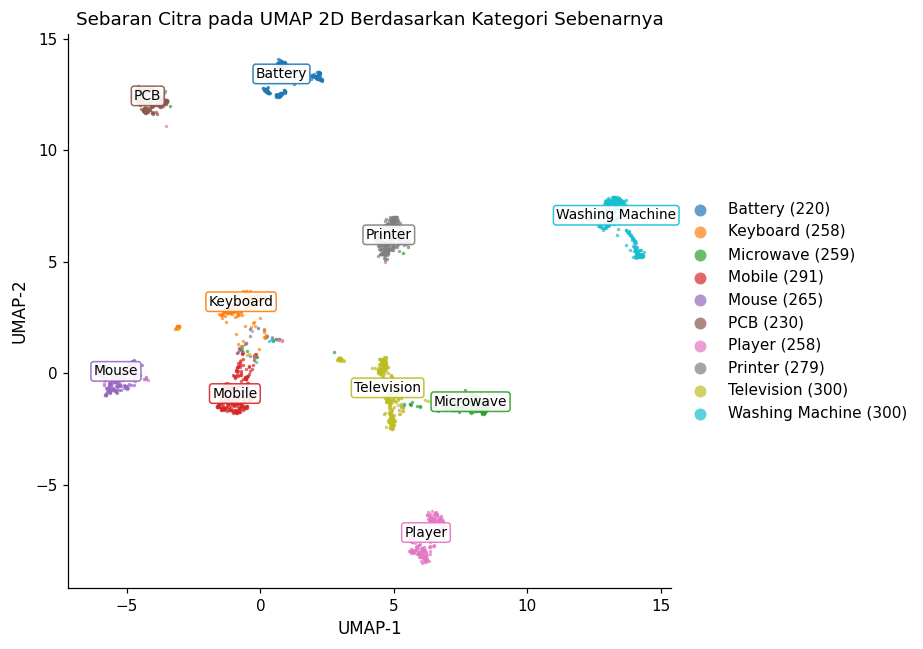

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for c in TARGET_CLASSES:
    m = y_true == c
    ax.scatter(X2[m, 0], X2[m, 1], s=5, alpha=0.7, lw=0, color=COL[c], label=f'{c} ({m.sum()})')
    ax.text(np.median(X2[m, 0]), np.median(X2[m, 1]), c, fontsize=9, ha='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=COL[c], alpha=0.9))
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2'); ax.set_title('Sebaran Citra pada UMAP 2D Berdasarkan Kategori Sebenarnya')
ax.legend(markerscale=3.5, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.show()

**Interpretasi.** Sebagian besar kategori membentuk kelompok yang terpisah jelas, yaitu Battery, PCB, Printer, Washing Machine, Mouse, dan Player. Keyboard dan Mobile berdekatan, sedangkan Microwave berada sangat dekat dengan Television. Kedekatan itulah yang nanti membuat keduanya bergabung dalam satu cluster pada subbab 4.6.

---
## 4.6 Proses dan Hasil Clustering dengan K-Means++ <a id='s46'></a>

K-Means++ dijalankan pada matriks UMAP 50 dimensi dengan `n_init = 10`. Jumlah cluster dipilih dari K = 2 sampai 25 berdasarkan Silhouette Score tertinggi:

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}, \qquad S=\frac{1}{n}\sum_{i=1}^{n}s(i)$$

dengan $a(i)$ adalah rata-rata jarak citra $i$ ke anggota lain pada clusternya, dan $b(i)$ adalah rata-rata jarak terkecil citra $i$ ke anggota cluster lain.

### 1. Penentuan jumlah cluster optimal

K,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
Silhouette,0.3435,0.4619,0.5535,0.6203,0.7011,0.7759,0.8001,0.8235,0.8211,0.8181,0.8044,0.7793,0.7885,0.7719,0.7499,0.7670,0.7774,0.7505,0.7024,0.6540,0.6649,0.6167,0.6126,0.6002
Inertia,105729.9844,74082.6719,50269.2969,34263.6523,18764.2969,10426.3838,4949.2573,2974.7058,1527.5637,1296.9290,1088.7107,923.8785,779.9132,681.2214,594.5242,534.9053,461.4866,425.5273,405.2722,371.4005,345.5711,319.2059,296.4998,281.7209
Iterasi,2.0000,2.0000,2.0000,2.0000,3.0000,2.0000,3.0000,2.0000,5.0000,5.0000,5.0000,6.0000,4.0000,7.0000,5.0000,4.0000,5.0000,6.0000,6.0000,6.0000,6.0000,9.0000,7.0000,6.0000


K terbaik = 9 dengan Silhouette Score = 0.8235


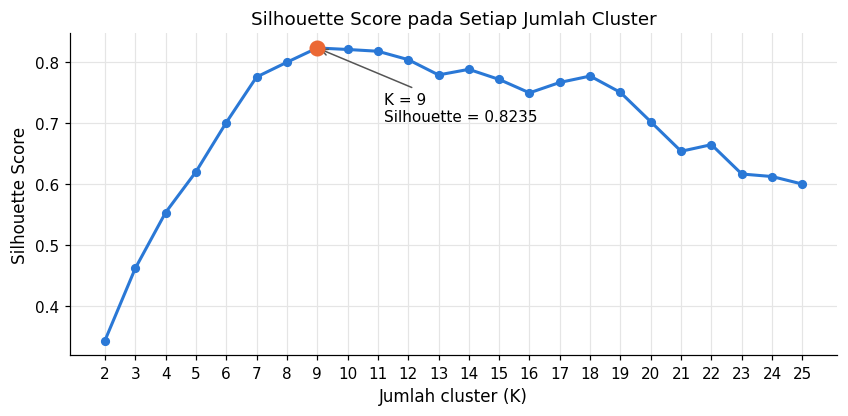

In [23]:
rows = []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X50)
    rows.append({'K': k, 'Silhouette': silhouette_score(X50, km_k.labels_), 'Inertia': km_k.inertia_, 'Iterasi': km_k.n_iter_})
tab_k = pd.DataFrame(rows)
display(tab_k.round(4).set_index('K').T)
K = int(tab_k.loc[tab_k['Silhouette'].idxmax(), 'K'])
print(f'K terbaik = {K} dengan Silhouette Score = {tab_k["Silhouette"].max():.4f}')

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(tab_k.K, tab_k.Silhouette, marker='o', ms=5, lw=2, color='#2a78d6')
ax.scatter([K], [tab_k.Silhouette.max()], s=90, color='#eb6834', zorder=5)
ax.annotate(f'K = {K}\nSilhouette = {tab_k.Silhouette.max():.4f}', (K, tab_k.Silhouette.max()),
            xytext=(K + 2.2, tab_k.Silhouette.max() - 0.12), arrowprops=dict(arrowstyle='->', color='#555'))
ax.set_xticks(tab_k.K); ax.set_xlabel('Jumlah cluster (K)'); ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Score pada Setiap Jumlah Cluster'); ax.grid(color='#e5e5e5'); plt.show()

### 2–4. Inisialisasi K-Means++, penentuan anggota, dan pembaruan centroid
Pusat berikutnya dipilih dengan peluang $P(x)=\dfrac{D(x)^2}{\sum_{x'} D(x')^2}$. Setiap citra dialokasikan ke centroid terdekat, $d(x,\mu_c)=\sqrt{\sum_{k=1}^{50}(x_k-\mu_{c,k})^2}$, lalu centroid diperbarui sebagai rata-rata anggotanya, $\mu_c=\frac{1}{|C_c|}\sum_{x\in C_c}x$.

In [24]:
km = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X50)
labels, C = km.labels_, km.cluster_centers_

# ── Inisialisasi K-Means++ (versi greedy scikit-learn) ─────────
_, idx0 = kmeans_plusplus(X50, n_clusters=K, random_state=SEED)
D2 = np.linalg.norm(X50 - X50[idx0[0]], axis=1) ** 2
judul('Inisialisasi K-Means++')
print(f'Kandidat per langkah (n_local_trials) = 2 + ⌊ln K⌋ = {int(2 + np.log(K))}')
print(f'Langkah ke-2: P(pusat terpilih) = {D2[idx0[1]]:.4f} / {D2.sum():.4f} = {D2[idx0[1]] / D2.sum():.6f}')
display(pd.DataFrame({'Pusat ke-': range(1, K + 1), 'Indeks': idx0,
                      'Nama file': [valid_names[j] for j in idx0], 'Kategori': y_true[idx0]}))

# ── Jarak citra sampel ke setiap centroid ──────────────────────
c_i = int(labels[SI]); d = np.linalg.norm(C - X50[SI], axis=1)
judul(f'Jarak Euclidean {SAMPLE_FILE} ke centroid cluster {c_i}')
print('d = √[' + ' + '.join(f'({X50[SI, k]:.4f} − {C[c_i, k]:.4f})²' for k in range(2)) + f' + … (50 suku)] = {d[c_i]:.4f}')
display(pd.DataFrame({'Cluster': range(K), 'Jarak': d.round(4)}).set_index('Cluster').T)
print(f'Jarak terkecil = {d.min():.4f} ke cluster {d.argmin()} → citra sampel masuk cluster {c_i}')

# ── Pembaruan centroid (dimensi pertama) ───────────────────────
mem = np.where(labels == c_i)[0]
judul(f'Pembaruan centroid cluster {c_i}, dimensi pertama')
print(f'μ = (' + ' + '.join(f'{X50[j, 0]:.4f}' for j in mem[:3]) + f' + … ) / {len(mem)} '
      f'= {X50[mem, 0].sum():.4f} / {len(mem)} = {X50[mem, 0].mean():.4f}   | centroid scikit-learn = {C[c_i, 0]:.4f}')
print(f'\nKonvergen setelah {km.n_iter_} iterasi, inertia = {km.inertia_:.2f}')

  Inisialisasi K-Means++
Kandidat per langkah (n_local_trials) = 2 + ⌊ln K⌋ = 4
Langkah ke-2: P(pusat terpilih) = 28.6653 / 265606.3125 = 0.000108


,Pusat ke-,Indeks,Nama file,Kategori
0,1,996,Mouse_280.jpg,Mouse
1,2,596,Mobile_17.jpg,Mobile
2,3,339,Microwave_171.jpg,Microwave
3,4,2629,pcb_63.jpg,PCB
4,5,1341,Printer_107.jpg,Printer
5,6,2067,Washing_Machine_24.jpg,Washing Machine
6,7,1330,Player_99.jpg,Player
7,8,2307,battery_259.jpg,Battery
8,9,25,Keyboard_120.jpg,Keyboard


  Jarak Euclidean Keyboard_0.jpg ke centroid cluster 8
d = √[(7.7551 − 8.0118)² + (6.0800 − 6.6910)² + … (50 suku)] = 0.8694


Cluster,0,1,2,3,4,5,6,7,8
Jarak,6.1783,4.1368,8.1614,11.455,10.6181,10.2535,10.2343,8.4015,0.8694


Jarak terkecil = 0.8694 ke cluster 8 → citra sampel masuk cluster 8
  Pembaruan centroid cluster 8, dimensi pertama
μ = (7.7551 + 7.7380 + 7.8245 + … ) / 273 = 2187.2107 / 273 = 8.0118   | centroid scikit-learn = 8.0118

Konvergen setelah 2 iterasi, inertia = 2974.71


### 5. Perhitungan Silhouette Score

In [25]:
s_i = silhouette_samples(X50, labels); sil = s_i.mean()
Dd = np.linalg.norm(X50 - X50[SI], axis=1); others = np.arange(len(Dd)) != SI
mean_d = {c: Dd[(labels == c) & others].mean() for c in range(K)}
a = mean_d[c_i]; b_c = min((c for c in range(K) if c != c_i), key=mean_d.get); b = mean_d[b_c]
judul(f'Silhouette citra sampel {SAMPLE_FILE}')
print(f'a(i) = rata-rata jarak ke {int((labels == c_i).sum()) - 1} anggota lain cluster {c_i} = {a:.4f}')
print(f'b(i) = rata-rata jarak ke cluster {b_c} (terkecil di antara cluster lain) = {b:.4f}')
print(f's(i) = ({b:.4f} − {a:.4f}) / max({a:.4f}, {b:.4f}) = {(b - a) / max(a, b):.4f}   | scikit-learn = {s_i[SI]:.4f}')
display(pd.DataFrame({'Cluster': range(K), 'Rata-rata jarak': [round(mean_d[c], 4) for c in range(K)]}).set_index('Cluster').T)
print(f'Silhouette keseluruhan S = {s_i.sum():.4f} / {len(s_i)} = {sil:.4f}')

  Silhouette citra sampel Keyboard_0.jpg
a(i) = rata-rata jarak ke 272 anggota lain cluster 8 = 1.0841
b(i) = rata-rata jarak ke cluster 1 (terkecil di antara cluster lain) = 4.1556
s(i) = (4.1556 − 1.0841) / max(1.0841, 4.1556) = 0.7391   | scikit-learn = 0.7391


Cluster,0,1,2,3,4,5,6,7,8
Rata-rata jarak,6.1894,4.1556,8.3513,11.4605,10.6261,10.2836,10.2571,8.4399,1.0841


Silhouette keseluruhan S = 2190.5588 / 2660 = 0.8235


### 6. Hasil clustering

,Cluster,Jumlah Citra,Kategori Mayoritas,Jumlah Mayoritas,Kemurnian (%),Rata-rata Silhouette,Silhouette Min
0,0,266,Mouse,261,98.12,0.8885,0.8233
1,1,322,Mobile,291,90.37,0.7406,0.0828
2,2,543,Television,296,54.51,0.7218,0.5164
3,3,232,PCB,227,97.84,0.9566,0.9434
4,4,274,Printer,272,99.27,0.9286,0.8966
5,5,295,Washing Machine,294,99.66,0.9030,0.8658
6,6,243,Player,242,99.59,0.8920,0.8583
7,7,212,Battery,212,100.00,0.8818,0.8649
8,8,273,Keyboard,244,89.38,0.6496,-0.0004


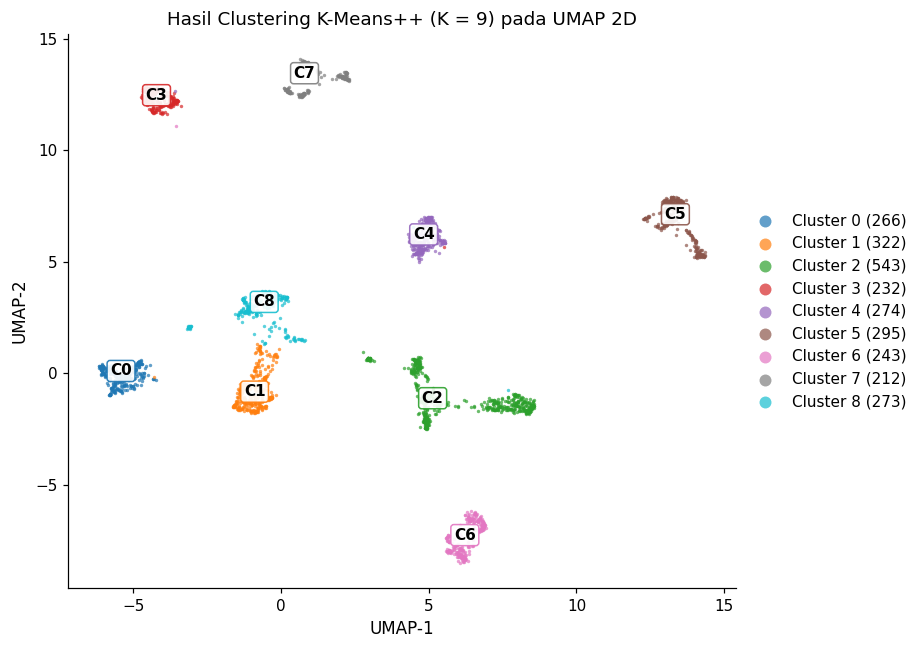

In [26]:
ct_lab = pd.crosstab(pd.Series(labels, name='Cluster'), pd.Series(y_true, name='Kategori')).reindex(columns=TARGET_CLASSES, fill_value=0)
tab_cl = pd.DataFrame({'Cluster': range(K), 'Jumlah Citra': ct_lab.sum(1).values,
                       'Kategori Mayoritas': ct_lab.idxmax(1).values, 'Jumlah Mayoritas': ct_lab.max(1).values,
                       'Kemurnian (%)': (ct_lab.max(1) / ct_lab.sum(1) * 100).round(2).values,
                       'Rata-rata Silhouette': [round(s_i[labels == c].mean(), 4) for c in range(K)],
                       'Silhouette Min': [round(s_i[labels == c].min(), 4) for c in range(K)]})
display(tab_cl)

CPAL = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#17becf', '#bcbd22']
fig, ax = plt.subplots(figsize=(8.5, 6))
for c in range(K):
    m = labels == c
    ax.scatter(X2[m, 0], X2[m, 1], s=5, alpha=0.7, lw=0, color=CPAL[c], label=f'Cluster {c} ({m.sum()})')
    ax.text(np.median(X2[m, 0]), np.median(X2[m, 1]), f'C{c}', fontweight='bold', ha='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=CPAL[c], alpha=0.9))
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2'); ax.set_title(f'Hasil Clustering K-Means++ (K = {K}) pada UMAP 2D')
ax.legend(markerscale=3.5, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.show()

**Interpretasi.** Silhouette Score naik dari 0,3435 (K = 2) hingga mencapai puncak **0,8235 pada K = 9**, lalu cenderung turun. Nilai pada K = 10 (0,8211) hanya sedikit lebih rendah. Delapan cluster didominasi satu kategori dengan kemurnian di atas 89%, bahkan cluster Battery murni 100%. Cluster terbesar (543 citra) menggabungkan Television dan Microwave, sesuai dengan kedekatan keduanya pada UMAP.

---
## 4.7 Bootstrap <a id='s47'></a>

Stabilitas cluster diuji dengan 50 kali *resampling* bootstrap. Pada setiap pengulangan, 2.660 titik diambil dengan pengembalian dari X50, lalu K-Means++ (K = 9) dijalankan ulang. Label bootstrap pada titik-titik unik dibandingkan dengan label data lengkap menggunakan ARI:

$$\text{ARI}=\frac{\sum_{ij}\binom{n_{ij}}{2}-\left[\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}\right]\Big/\binom{n}{2}}{\frac{1}{2}\left[\sum_i\binom{a_i}{2}+\sum_j\binom{b_j}{2}\right]-\left[\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}\right]\Big/\binom{n}{2}}$$

,+1,+2,+3,+4,+5,+6,+7,+8,+9,+10
Bootstrap ke- = baris + kolom,,,,,,,,,,
0,1.0000,1.0000,1.0000,1.0000,0.9987,1.0000,1.0,1.0,1.0000,1.0
10,1.0000,1.0000,1.0000,1.0000,0.9988,1.0000,1.0,1.0,0.9988,1.0
20,1.0000,0.9987,1.0000,0.9987,0.9988,1.0000,1.0,1.0,1.0000,1.0
30,1.0000,1.0000,0.9987,1.0000,1.0000,1.0000,1.0,1.0,1.0000,1.0
40,0.9988,1.0000,0.9988,1.0000,1.0000,0.9988,1.0,1.0,0.9987,1.0


Rata-rata ARI = 0.9997 | simpangan baku = 0.0005 | min = 0.9987 | maks = 1.0000
Selang persentil 95% = [0.9987, 1.0000] | ARI = 1 pada 39 dari 50 pengulangan


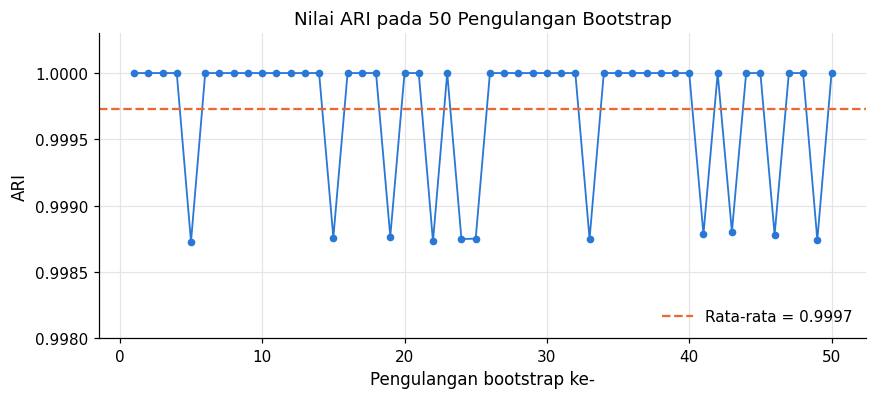

In [27]:
rng = np.random.RandomState(SEED); n = len(X50); rows, tables = [], {}
for b in range(N_BOOT):
    idx = rng.choice(n, size=n, replace=True)
    lab_b = KMeans(n_clusters=K, random_state=SEED + b + 1, n_init=10).fit_predict(X50[idx])
    uniq, first = np.unique(idx, return_index=True)
    rows.append({'Bootstrap ke-': b + 1, 'Titik unik': len(uniq), 'ARI': adjusted_rand_score(labels[uniq], lab_b[first])})
    tables[b + 1] = pd.crosstab(pd.Series(labels[uniq], name='Data lengkap'), pd.Series(lab_b[first], name='Bootstrap'))
tab_boot = pd.DataFrame(rows)
b_min = int(tab_boot.loc[tab_boot['ARI'].idxmin(), 'Bootstrap ke-'])
lo, hi = np.percentile(tab_boot['ARI'], [2.5, 97.5])
display(pd.DataFrame(tab_boot.ARI.values.reshape(5, 10).round(4), columns=[f'+{q}' for q in range(1, 11)],
                     index=[r * 10 for r in range(5)]).rename_axis('Bootstrap ke- = baris + kolom'))
print(f'Rata-rata ARI = {tab_boot.ARI.mean():.4f} | simpangan baku = {tab_boot.ARI.std(ddof=0):.4f} | '
      f'min = {tab_boot.ARI.min():.4f} | maks = {tab_boot.ARI.max():.4f}')
print(f'Selang persentil 95% = [{lo:.4f}, {hi:.4f}] | ARI = 1 pada {(tab_boot.ARI >= 0.99999).sum()} dari {N_BOOT} pengulangan')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tab_boot['Bootstrap ke-'], tab_boot.ARI, marker='o', ms=4, lw=1.2, color='#2a78d6')
ax.axhline(tab_boot.ARI.mean(), color='#eb6834', ls='--', label=f'Rata-rata = {tab_boot.ARI.mean():.4f}')
ax.set_ylim(0.998, 1.0003); ax.set_xlabel('Pengulangan bootstrap ke-'); ax.set_ylabel('ARI')
ax.set_title('Nilai ARI pada 50 Pengulangan Bootstrap'); ax.legend(frameon=False, loc='lower right'); ax.grid(color='#e5e5e5')
plt.show()

In [28]:
# ── Perhitungan manual ARI pada pengulangan dengan ARI terendah ─
def ari_manual(ct, cetak=True):
    ct = np.asarray(ct, dtype=np.float64); c2 = lambda v: v * (v - 1) / 2
    n = ct.sum(); s_ij = c2(ct).sum(); s_a = c2(ct.sum(1)).sum(); s_b = c2(ct.sum(0)).sum(); tot = c2(n)
    exp = s_a * s_b / tot; mx = (s_a + s_b) / 2; ari = (s_ij - exp) / (mx - exp)
    if cetak:
        print(f'n = {n:,.0f} ; C(n,2) = {tot:,.0f}')
        print(f'Σ C(n_ij,2) = {s_ij:,.0f} ; Σ C(a_i,2) = {s_a:,.0f} ; Σ C(b_j,2) = {s_b:,.0f}')
        print(f'Indeks harapan = {s_a:,.0f} × {s_b:,.0f} / {tot:,.0f} = {exp:,.4f}')
        print(f'Indeks maksimum = ({s_a:,.0f} + {s_b:,.0f}) / 2 = {mx:,.1f}')
        print(f'ARI = ({s_ij:,.0f} − {exp:,.4f}) / ({mx:,.1f} − {exp:,.4f}) = {ari:.4f}')
    return ari

judul(f'Tabel kontingensi bootstrap ke-{b_min} (ARI terendah)')
display(tables[b_min])
ari_b = ari_manual(tables[b_min])
print(f'ARI scikit-learn = {tab_boot.loc[tab_boot["Bootstrap ke-"] == b_min, "ARI"].iloc[0]:.4f}')

  Tabel kontingensi bootstrap ke-5 (ARI terendah)


Bootstrap,0,1,2,3,4,5,6,7,8
Data lengkap,,,,,,,,,
0,0,0,0,0,0,0,0,174,0
1,219,0,0,0,0,0,0,0,1
2,0,0,0,328,0,0,0,0,0
3,0,0,0,0,144,0,0,0,0
4,0,0,0,0,0,182,0,0,0
5,0,0,185,0,0,0,0,0,0
6,0,159,0,0,0,0,0,0,0
7,0,0,0,0,0,0,135,0,0
8,0,0,0,0,0,0,0,0,166


n = 1,693 ; C(n,2) = 1,432,278
Σ C(n_ij,2) = 171,638 ; Σ C(a_i,2) = 171,857 ; Σ C(b_j,2) = 171,804
Indeks harapan = 171,857 × 171,804 / 1,432,278 = 20,614.5176
Indeks maksimum = (171,857 + 171,804) / 2 = 171,830.5
ARI = (171,638 − 20,614.5176) / (171,830.5 − 20,614.5176) = 0.9987
ARI scikit-learn = 0.9987


**Interpretasi.** Sebanyak 39 dari 50 pengulangan menghasilkan ARI sempurna (1), dan 11 sisanya menghasilkan ARI sekitar 0,9987–0,9988. Pada pengulangan yang tidak sempurna, hanya satu titik yang berpindah cluster. Dengan rata-rata ARI 0,9997, struktur sembilan cluster **sangat stabil** terhadap perubahan sampel.

---
## 4.8 Pelabelan Cluster menggunakan CLIP Zero-Shot <a id='s48'></a>

Setiap cluster diberi nama secara otomatis dengan membandingkan embedding citra anggotanya terhadap embedding teks deskripsi kategori. Text encoder CLIP yang dipakai sama, dan tahap ini **tidak memakai label sebenarnya**.

### 4.8.1 Penyusunan prompt untuk setiap kelas

In [29]:
PROMPTS = [f'a photo of {c}' for c in TARGET_CLASSES]
display(pd.DataFrame({'Kategori': TARGET_CLASSES, 'Prompt': PROMPTS}))

,Kategori,Prompt
0,Battery,a photo of Battery
1,Keyboard,a photo of Keyboard
2,Microwave,a photo of Microwave
3,Mobile,a photo of Mobile
4,Mouse,a photo of Mouse
5,PCB,a photo of PCB
6,Player,a photo of Player
7,Printer,a photo of Printer
8,Television,a photo of Television
9,Washing Machine,a photo of Washing Machine


### 4.8.2 Tokenisasi prompt
Tokenizer CLIP berbasis *Byte Pair Encoding* dengan 49.408 token. Setiap prompt diapit token awal `<start_of_text>` dan token akhir `<end_of_text>`, lalu diberi *padding* hingga panjang 77.

In [30]:
toks = tokenizer(PROMPTS)
dec = getattr(getattr(tokenizer, 'tokenizer', tokenizer), 'decoder', None) or getattr(tokenizer, 'decoder', {})
rows = []
for p, t in zip(PROMPTS, toks):
    ids = [int(v) for v in t if int(v) != 0]
    rows.append({'Prompt': p, 'Jumlah token': len(ids), 'ID token': ids, 'Token': [dec.get(v, '?') for v in ids]})
display(pd.DataFrame(rows))
print('Ukuran tensor token:', tuple(toks.shape))

,Prompt,Jumlah token,ID token,Token
0,a photo of Battery,6,"[49406, 320, 1125, 539, 7870, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, ba..."
1,a photo of Keyboard,6,"[49406, 320, 1125, 539, 13017, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, ke..."
2,a photo of Microwave,6,"[49406, 320, 1125, 539, 24240, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, mi..."
3,a photo of Mobile,6,"[49406, 320, 1125, 539, 3451, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, mo..."
4,a photo of Mouse,6,"[49406, 320, 1125, 539, 9301, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, mo..."
5,a photo of PCB,6,"[49406, 320, 1125, 539, 26235, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, pc..."
6,a photo of Player,6,"[49406, 320, 1125, 539, 2477, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, pl..."
7,a photo of Printer,6,"[49406, 320, 1125, 539, 14521, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, pr..."
8,a photo of Television,6,"[49406, 320, 1125, 539, 8608, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, te..."
9,a photo of Washing Machine,7,"[49406, 320, 1125, 539, 13029, 4169, 49407]","[<start_of_text>, a</w>, photo</w>, of</w>, wa..."


Ukuran tensor token: (10, 77)


### 4.8.3 Ekstraksi dan normalisasi embedding teks
Embedding teks diambil dari keluaran `ln_final` pada posisi token `<end_of_text>`, lalu diproyeksikan dengan `text_projection` berukuran 1.024×1.024 dan dinormalisasi L2.

In [31]:
cap = {}
h1 = model.ln_final.register_forward_hook(lambda m, i, o: cap.__setitem__('lnf', o.detach()) or None)
with torch.no_grad():
    T = model.encode_text(toks.to(DEVICE)).float().cpu()
h1.remove()
Tn = T / T.norm(dim=-1, keepdim=True)
p = TARGET_CLASSES.index(y_true[SI]); eot = int(toks[p].argmax())
lnf = cap['lnf'].float().cpu()[p]
TP = model.text_projection; TP = (TP.weight.T if hasattr(TP, 'weight') else TP).detach().float().cpu()
h = lnf[eot]; zt = h @ TP
judul(f'Embedding teks "{PROMPTS[p]}" (token <end_of_text> di posisi {eot})')
print('z_1 = ' + ' + '.join(f'({h[k]:.4f})({TP[k, 0]:.4f})' for k in range(2)) + f' + … (1.024 suku) = {zt[0]:.4f}'
      f'   | encode_text = {T[p, 0]:.4f}')
print(f'Norma L2 = {T[p].norm():.4f} → vektor ternormalisasi: {ringkas(Tn[p])}')
display(pd.DataFrame({'Prompt': PROMPTS, 'Norma sebelum': T.norm(dim=-1).numpy().round(4),
                      'Norma sesudah': Tn.norm(dim=-1).numpy().round(4)}))

  Embedding teks "a photo of Keyboard" (token <end_of_text> di posisi 5)
z_1 = (0.6330)(-0.0003) + (0.4412)(0.0185) + … (1.024 suku) = 0.6926   | encode_text = 0.6926
Norma L2 = 19.0124 → vektor ternormalisasi: [0.0364, -0.0183, 0.0212, …, 0.0239, 0.0168, 0.0026]  (panjang 1024)


,Prompt,Norma sebelum,Norma sesudah
0,a photo of Battery,16.003500,1.0
1,a photo of Keyboard,19.012400,1.0
2,a photo of Microwave,17.963499,1.0
3,a photo of Mobile,14.683100,1.0
4,a photo of Mouse,16.963499,1.0
5,a photo of PCB,18.212799,1.0
6,a photo of Player,14.414100,1.0
7,a photo of Printer,18.505199,1.0
8,a photo of Television,18.767000,1.0
9,a photo of Washing Machine,19.383101,1.0


### 4.8.4 Perhitungan kemiripan embedding citra dan teks
Karena kedua embedding sudah dinormalisasi L2, *cosine similarity* sama dengan hasil kali titik: $\text{sim}(i,t)=\hat{\mathbf{e}}_i\cdot\hat{\mathbf{t}}_t$.

In [32]:
IMG_TEXT_SIM = emb_l2 @ Tn.numpy().T            # 2.660 × 10
vi, tt = emb_l2[SI].astype(np.float64), Tn[p].numpy().astype(np.float64)
judul(f'Kemiripan {SAMPLE_FILE} dengan "{PROMPTS[p]}"')
print('sim = ' + ' + '.join(f'({vi[k]:.4f})({tt[k]:.4f})' for k in range(2)) + f' + … (1.024 suku) = {vi @ tt:.4f}')
display(pd.DataFrame({'Prompt': PROMPTS, 'Cosine similarity': IMG_TEXT_SIM[SI].round(4)})
        .sort_values('Cosine similarity', ascending=False).reset_index(drop=True))

  Kemiripan Keyboard_0.jpg dengan "a photo of Keyboard"
sim = (-0.0204)(0.0364) + (-0.0156)(-0.0183) + … (1.024 suku) = 0.2104


,Prompt,Cosine similarity
0,a photo of Keyboard,0.2104
1,a photo of Mobile,0.1421
2,a photo of Mouse,0.1420
3,a photo of Printer,0.1155
4,a photo of PCB,0.1124
5,a photo of Player,0.1025
6,a photo of Television,0.0795
7,a photo of Battery,0.0528
8,a photo of Washing Machine,0.0410
9,a photo of Microwave,0.0392


### 4.8.5 Perataan skor kemiripan pada setiap cluster
$$\bar{s}_{c,t}=\frac{1}{|C_c|}\sum_{i\in C_c}\text{sim}(i,t)$$

  Rata-rata kemiripan cluster 8 terhadap "a photo of Keyboard"
s̄ = (0.2104 + 0.2352 + 0.2463 + … ) / 273 = 67.9842 / 273 = 0.2490


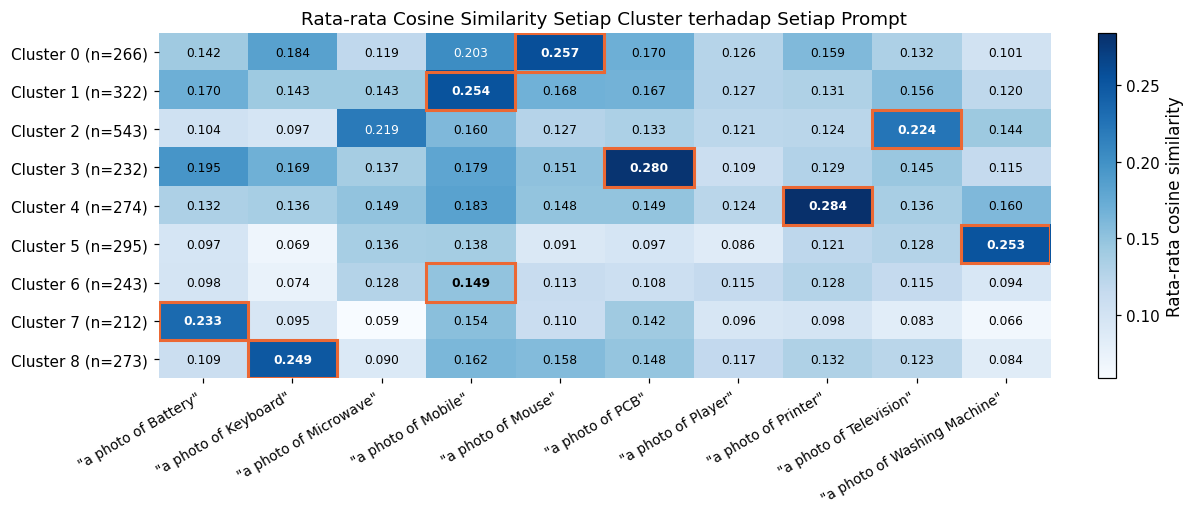

In [33]:
memc = np.where(labels == c_i)[0]
judul(f'Rata-rata kemiripan cluster {c_i} terhadap "{PROMPTS[p]}"')
print('s̄ = (' + ' + '.join(f'{IMG_TEXT_SIM[j, p]:.4f}' for j in memc[:3]) + f' + … ) / {len(memc)} = '
      f'{IMG_TEXT_SIM[memc, p].sum():.4f} / {len(memc)} = {IMG_TEXT_SIM[memc, p].mean():.4f}')
S = np.vstack([IMG_TEXT_SIM[labels == c].mean(0) for c in range(K)])
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(S, cmap='Blues', aspect='auto')
for r in range(K):
    for q in range(len(TARGET_CLASSES)):
        ax.text(q, r, f'{S[r, q]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if S[r, q] > 0.2 else 'black', fontweight='bold' if q == S[r].argmax() else 'normal')
    ax.add_patch(plt.Rectangle((S[r].argmax() - 0.5, r - 0.5), 1, 1, fill=False, ec='#eb6834', lw=2))
ax.set_xticks(range(10)); ax.set_xticklabels([f'"{t}"' for t in PROMPTS], rotation=30, ha='right', fontsize=9)
ax.set_yticks(range(K)); ax.set_yticklabels([f'Cluster {c} (n={int((labels == c).sum())})' for c in range(K)])
ax.spines[:].set_visible(False); fig.colorbar(im, ax=ax, fraction=0.025, label='Rata-rata cosine similarity')
ax.set_title('Rata-rata Cosine Similarity Setiap Cluster terhadap Setiap Prompt'); plt.tight_layout(); plt.show()

### 4.8.6 Penetapan label cluster berdasarkan skor tertinggi
$$\text{label}(c)=\arg\max_{t}\ \bar{s}_{c,t}$$
Kategori mayoritas dicantumkan **hanya sebagai pembanding** dan tidak dipakai dalam penetapan label.

In [34]:
srt = np.sort(S, axis=1)
tab_zs = pd.DataFrame({'Cluster': range(K), 'Jumlah Citra': [int((labels == c).sum()) for c in range(K)],
                       'Label Zero-Shot': [TARGET_CLASSES[q] for q in S.argmax(1)],
                       'Skor Tertinggi': srt[:, -1].round(4), 'Margin ke Skor Kedua': (srt[:, -1] - srt[:, -2]).round(4),
                       'Kategori Mayoritas': tab_cl['Kategori Mayoritas'].values})
tab_zs['Sesuai?'] = np.where(tab_zs['Label Zero-Shot'] == tab_zs['Kategori Mayoritas'], 'Ya', 'Tidak')
display(tab_zs)
mapping = dict(zip(tab_zs['Cluster'], tab_zs['Label Zero-Shot']))
print(f'Jumlah label unik: {len(set(mapping.values()))} untuk {K} cluster')

,Cluster,Jumlah Citra,Label Zero-Shot,Skor Tertinggi,Margin ke Skor Kedua,Kategori Mayoritas,Sesuai?
0,0,266,Mouse,0.2574,0.0544,Mouse,Ya
1,1,322,Mobile,0.2540,0.0841,Mobile,Ya
2,2,543,Television,0.2239,0.0049,Television,Ya
3,3,232,PCB,0.2802,0.0848,PCB,Ya
4,4,274,Printer,0.2839,0.1008,Printer,Ya
5,5,295,Washing Machine,0.2531,0.1151,Washing Machine,Ya
6,6,243,Mobile,0.1495,0.0219,Player,Tidak
7,7,212,Battery,0.2331,0.0788,Battery,Ya
8,8,273,Keyboard,0.2490,0.0869,Keyboard,Ya


Jumlah label unik: 8 untuk 9 cluster


**Interpretasi.** Label zero-shot sesuai dengan kategori mayoritas pada delapan cluster. Satu-satunya yang keliru adalah cluster Player (242 dari 243 citranya Player), yang justru diberi label **Mobile** dengan margin kecil. Akibatnya hanya delapan label unik yang muncul, dan kategori Player tidak pernah diprediksi. Kesalahan ini muncul pada tahap pemberian nama, bukan pada tahap clustering (dibahas pada subbab 4.10).

---
## 4.9 Metrik Evaluasi Eksternal <a id='s49'></a>

Evaluasi dilakukan pada dua tingkat:
- **tingkat cluster**: *purity* dan ARI antara nomor cluster dan kategori sebenarnya;
- **tingkat label**: akurasi, precision, recall, F1-Score, dan ARI antara label zero-shot dan kategori sebenarnya.

$$\text{Purity}=\frac{1}{n}\sum_{c}\max_{j}\,n_{cj}, \qquad \text{Akurasi}=\frac{\sum_j \text{TP}_j}{n}, \qquad F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

In [35]:
judul('Tabel kontingensi cluster × kategori sebenarnya')
display(ct_lab)
judul('1) Purity')
print('Purity = (' + ' + '.join(str(v) for v in ct_lab.max(1)) + f') / {ct_lab.values.sum()} = '
      f'{ct_lab.max(1).sum()} / {ct_lab.values.sum()} = {ct_lab.max(1).sum() / ct_lab.values.sum():.4f}')
judul('2) ARI nomor cluster terhadap kategori sebenarnya')
ari_c = ari_manual(ct_lab)
print(f'ARI scikit-learn = {adjusted_rand_score(y_true, labels):.4f}')

  Tabel kontingensi cluster × kategori sebenarnya


Kategori,Battery,Keyboard,Microwave,Mobile,Mouse,PCB,Player,Printer,Television,Washing Machine
Cluster,,,,,,,,,,
0,0,0,0,0,261,0,5,0,0,0
1,1,14,3,291,4,3,0,1,3,2
2,0,0,244,0,0,0,2,0,296,1
3,1,0,2,0,0,227,1,1,0,0
4,0,0,1,0,0,0,1,272,0,0
5,0,0,1,0,0,0,0,0,0,294
6,0,0,1,0,0,0,242,0,0,0
7,212,0,0,0,0,0,0,0,0,0
8,6,244,7,0,0,0,7,5,1,3


  1) Purity
Purity = (261 + 291 + 296 + 227 + 272 + 294 + 242 + 212 + 244) / 2660 = 2339 / 2660 = 0.8793
  2) ARI nomor cluster terhadap kategori sebenarnya
n = 2,660 ; C(n,2) = 3,536,470
Σ C(n_ij,2) = 336,371 ; Σ C(a_i,2) = 430,538 ; Σ C(b_j,2) = 355,798
Indeks harapan = 430,538 × 355,798 / 3,536,470 = 43,315.6677
Indeks maksimum = (430,538 + 355,798) / 2 = 393,168.0
ARI = (336,371 − 43,315.6677) / (393,168.0 − 43,315.6677) = 0.8377
ARI scikit-learn = 0.8377


In [36]:
y_pred = np.array([mapping[c] for c in labels])
cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=TARGET_CLASSES), index=TARGET_CLASSES, columns=TARGET_CLASSES)
cm.index.name, cm.columns.name = 'Sebenarnya', 'Prediksi'
judul('3) Confusion matrix kategori sebenarnya × label zero-shot')
display(cm)
tp = np.trace(cm.values)
print(f'Akurasi = {tp} / {cm.values.sum()} = {tp / cm.values.sum():.4f}')

j = TARGET_CLASSES.index('Mobile'); TPm = cm.values[j, j]; FPm = cm.values[:, j].sum() - TPm; FNm = cm.values[j].sum() - TPm
pm, rm = TPm / (TPm + FPm), TPm / (TPm + FNm)
print(f'\nKategori Mobile: TP = {TPm}, FP = {FPm}, FN = {FNm}')
print(f'Precision = {TPm} / ({TPm} + {FPm}) = {pm:.4f} ; Recall = {TPm} / ({TPm} + {FNm}) = {rm:.4f}')
print(f'F1 = 2 × {pm:.4f} × {rm:.4f} / ({pm:.4f} + {rm:.4f}) = {2 * pm * rm / (pm + rm):.4f}')

pr, rc, f1, sp = precision_recall_fscore_support(y_true, y_pred, labels=TARGET_CLASSES, zero_division=0)
tab_pc = pd.DataFrame({'Kategori': TARGET_CLASSES, 'Precision': pr, 'Recall': rc, 'F1-Score': f1, 'Support': sp}).round(4)
display(tab_pc)

  3) Confusion matrix kategori sebenarnya × label zero-shot


Prediksi,Battery,Keyboard,Microwave,Mobile,Mouse,PCB,Player,Printer,Television,Washing Machine
Sebenarnya,,,,,,,,,,
Battery,212,6,0,1,0,1,0,0,0,0
Keyboard,0,244,0,14,0,0,0,0,0,0
Microwave,0,7,0,4,0,2,0,1,244,1
Mobile,0,0,0,291,0,0,0,0,0,0
Mouse,0,0,0,4,261,0,0,0,0,0
PCB,0,0,0,3,0,227,0,0,0,0
Player,0,7,0,242,5,1,0,1,2,0
Printer,0,5,0,1,0,1,0,272,0,0
Television,0,1,0,3,0,0,0,0,296,0


Akurasi = 2097 / 2660 = 0.7883

Kategori Mobile: TP = 291, FP = 274, FN = 0
Precision = 291 / (291 + 274) = 0.5150 ; Recall = 291 / (291 + 0) = 1.0000
F1 = 2 × 0.5150 × 1.0000 / (0.5150 + 1.0000) = 0.6799


,Kategori,Precision,Recall,F1-Score,Support
0,Battery,1.0000,0.9636,0.9815,220
1,Keyboard,0.8938,0.9457,0.9190,258
2,Microwave,0.0000,0.0000,0.0000,259
3,Mobile,0.5150,1.0000,0.6799,291
4,Mouse,0.9812,0.9849,0.9831,265
5,PCB,0.9784,0.9870,0.9827,230
6,Player,0.0000,0.0000,0.0000,258
7,Printer,0.9927,0.9749,0.9837,279
8,Television,0.5451,0.9867,0.7023,300
9,Washing Machine,0.9966,0.9800,0.9882,300


In [37]:
metrik = {'Purity': ct_lab.max(1).sum() / ct_lab.values.sum(),
          'ARI (nomor cluster)': adjusted_rand_score(y_true, labels),
          'NMI (nomor cluster)': normalized_mutual_info_score(y_true, labels),
          'Akurasi (label zero-shot)': accuracy_score(y_true, y_pred),
          'F1-Score makro': f1_score(y_true, y_pred, labels=TARGET_CLASSES, average='macro', zero_division=0),
          'F1-Score tertimbang': f1_score(y_true, y_pred, labels=TARGET_CLASSES, average='weighted', zero_division=0),
          'ARI (label zero-shot)': adjusted_rand_score(y_true, y_pred)}
display(pd.DataFrame(metrik.items(), columns=['Metrik', 'Nilai']).round(4))

,Metrik,Nilai
0,Purity,0.8793
1,ARI (nomor cluster),0.8377
2,NMI (nomor cluster),0.9021
3,Akurasi (label zero-shot),0.7883
4,F1-Score makro,0.7220
5,F1-Score tertimbang,0.7214
6,ARI (label zero-shot),0.7483


**Interpretasi.** Pada tingkat cluster, *purity* 0,8793 berarti 87,93% citra berada pada cluster yang didominasi kategorinya sendiri, dan ARI 0,8377 menunjukkan kesesuaian tinggi dengan kategori sebenarnya. Pada tingkat label, akurasi turun menjadi 0,7883 dan F1 makro menjadi 0,7220. Penurunan ini terutama disebabkan oleh dua hal: cluster Player diberi label Mobile, dan citra Microwave ikut berlabel Television.

---
## 4.10 Analisis Hasil Cluster <a id='s410'></a>

Contoh citra anggota setiap cluster ditampilkan di bawah. Setelah itu, setiap cluster dikelompokkan ke dalam tiga kondisi: **murni dan diberi label tepat**, **menggabungkan kategori yang mirip secara visual**, dan **murni tetapi diberi label keliru**.

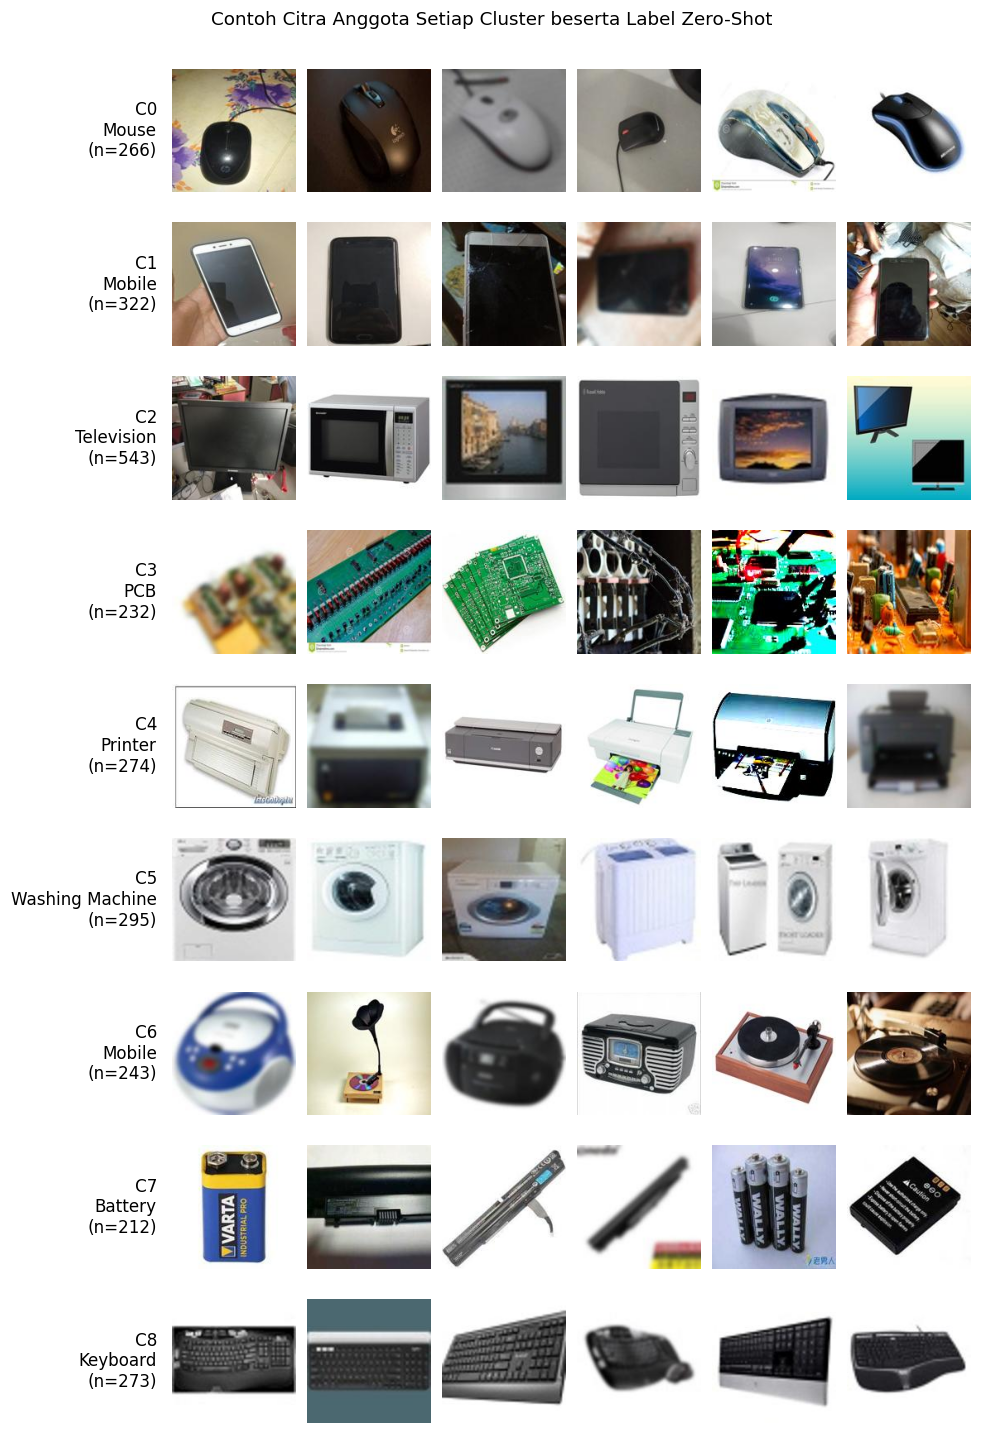

In [38]:
def thumb(f, s=160):
    im = Image.open(DATASET_DIR / f).convert('RGB'); im.thumbnail((s, s)); return im
rng = np.random.RandomState(SEED)
fig, axs = plt.subplots(K, 6, figsize=(9, 1.45 * K))
for c in range(K):
    idx = np.where(labels == c)[0]
    for jj, k in enumerate(rng.choice(idx, 6, replace=False)):
        axs[c, jj].imshow(thumb(valid_names[k])); axs[c, jj].set_xticks([]); axs[c, jj].set_yticks([])
        for s in axs[c, jj].spines.values(): s.set_visible(False)
    axs[c, 0].set_ylabel(f'C{c}\n{mapping[c]}\n(n={len(idx)})', rotation=0, ha='right', va='center', labelpad=10)
plt.suptitle('Contoh Citra Anggota Setiap Cluster beserta Label Zero-Shot', y=1.0); plt.tight_layout(); plt.show()

In [39]:
# ── Pengelompokan kondisi cluster ──────────────────────────────
def kondisi(r):
    if r['Label Zero-Shot'] != r['Kategori Mayoritas']: return '3. Murni, label keliru'
    if r['Kemurnian (%)'] >= 97: return '1. Murni, label tepat'
    return '2. Gabungan kategori mirip'
tab_an = tab_cl.merge(tab_zs[['Cluster', 'Label Zero-Shot', 'Margin ke Skor Kedua']], on='Cluster')
tab_an['Kondisi'] = tab_an.apply(kondisi, axis=1)
lain = ct_lab.apply(lambda r: ', '.join(f'{k} ({v})' for k, v in r.items() if v > 0 and k != r.idxmax()) or '—', axis=1)
tab_an['Kategori lain di dalam cluster'] = lain.values
display(tab_an[['Cluster', 'Kondisi', 'Label Zero-Shot', 'Kategori Mayoritas', 'Kemurnian (%)',
                'Rata-rata Silhouette', 'Kategori lain di dalam cluster']].sort_values(['Kondisi', 'Cluster']))

,Cluster,Kondisi,Label Zero-Shot,Kategori Mayoritas,Kemurnian (%),Rata-rata Silhouette,Kategori lain di dalam cluster
0,0,"1. Murni, label tepat",Mouse,Mouse,98.12,0.8885,Player (5)
3,3,"1. Murni, label tepat",PCB,PCB,97.84,0.9566,"Battery (1), Microwave (2), Player (1), Printe..."
4,4,"1. Murni, label tepat",Printer,Printer,99.27,0.9286,"Microwave (1), Player (1)"
5,5,"1. Murni, label tepat",Washing Machine,Washing Machine,99.66,0.9030,Microwave (1)
7,7,"1. Murni, label tepat",Battery,Battery,100.00,0.8818,—
1,1,2. Gabungan kategori mirip,Mobile,Mobile,90.37,0.7406,"Battery (1), Keyboard (14), Microwave (3), Mou..."
2,2,2. Gabungan kategori mirip,Television,Television,54.51,0.7218,"Microwave (244), Player (2), Washing Machine (1)"
8,8,2. Gabungan kategori mirip,Keyboard,Keyboard,89.38,0.6496,"Battery (6), Microwave (7), Player (7), Printe..."
6,6,"3. Murni, label keliru",Mobile,Player,99.59,0.8920,Microwave (1)


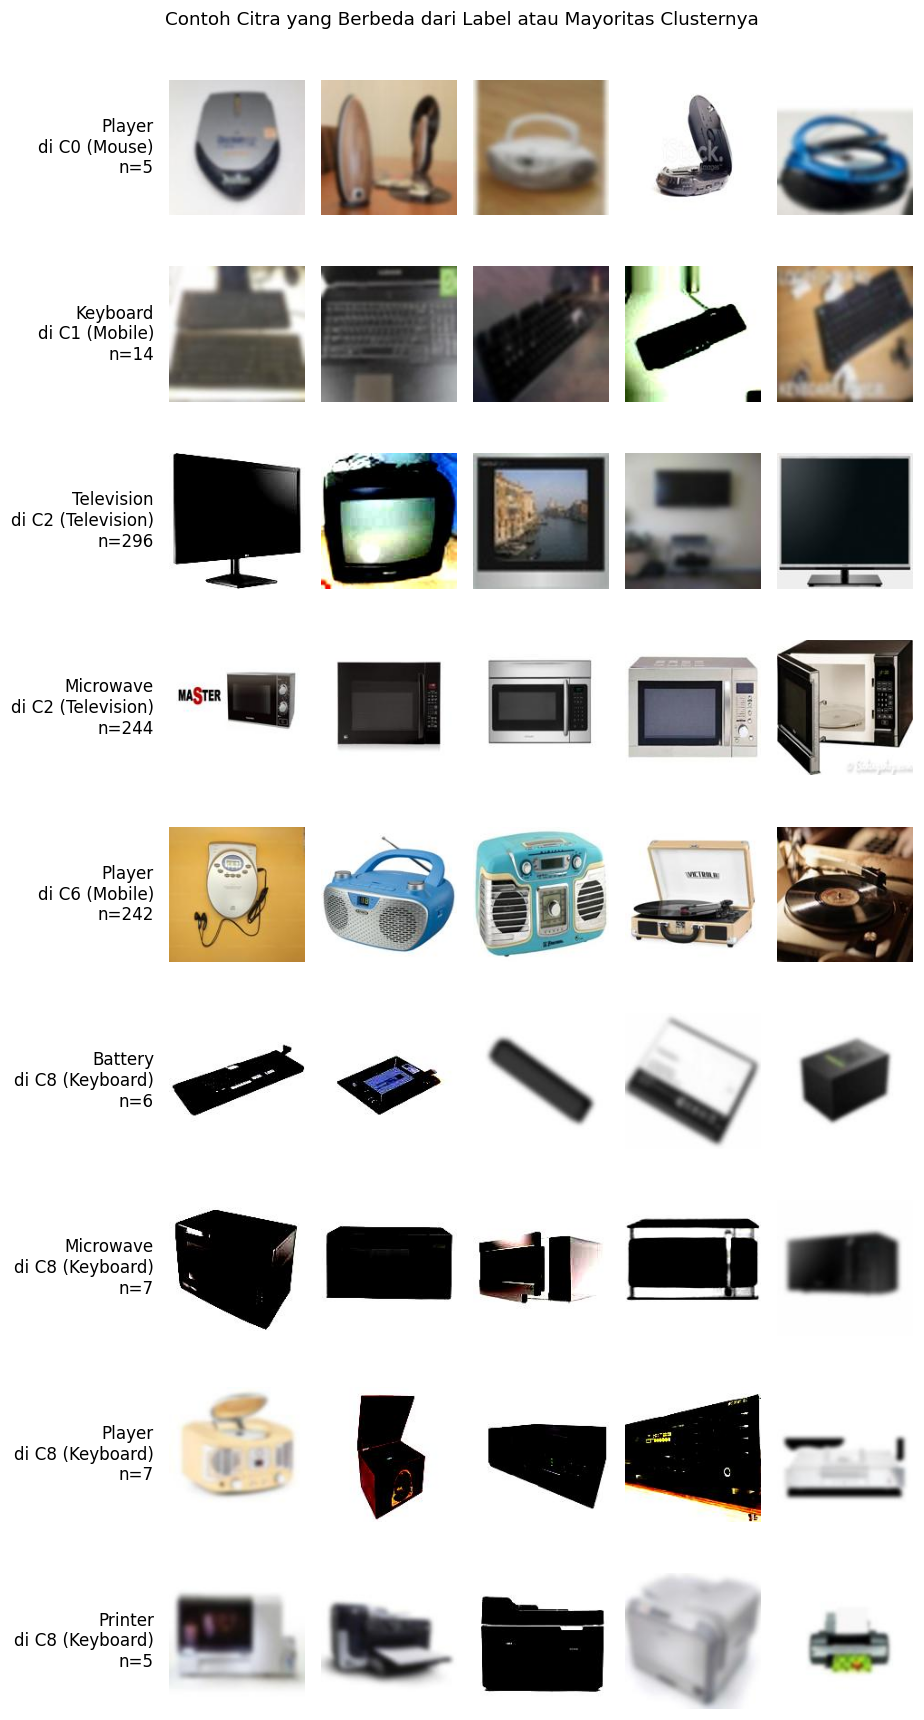

Skor rata-rata cluster 6 (mayoritas Player) terhadap setiap prompt:


,Rata-rata similarity
a photo of Mobile,0.1495
a photo of Printer,0.1276
a photo of Microwave,0.1276
a photo of Player,0.1153
a photo of Television,0.1151
a photo of Mouse,0.1128
a photo of PCB,0.1077
a photo of Battery,0.0978
a photo of Washing Machine,0.0936
a photo of Keyboard,0.0742


In [40]:
# ── Contoh citra yang tergabung dengan kategori lain ───────────
cases = [(c, k) for c in range(K) for k in TARGET_CLASSES
         if ct_lab.loc[c, k] >= 5 and (k != tab_cl.loc[c, 'Kategori Mayoritas'] or mapping[c] != k)]
# cluster gabungan (kategori kedua >= 20 citra): tampilkan juga kategori mayoritasnya sebagai pembanding
for c in range(K):
    maj = tab_cl.loc[c, 'Kategori Mayoritas']
    if (ct_lab.loc[c].drop(maj) >= 20).any() and (c, maj) not in cases:
        cases.insert(cases.index(next(x for x in cases if x[0] == c)), (c, maj))
fig, axs = plt.subplots(len(cases), 5, figsize=(8.5, 1.75 * len(cases)))
axs = np.atleast_2d(axs)
for r, (c, k) in enumerate(cases):
    idx = np.where((labels == c) & (y_true == k))[0]
    pick = idx if len(idx) <= 5 else rng.choice(idx, 5, replace=False)
    for jj in range(5):
        a = axs[r, jj]; a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)
        if jj < len(pick): a.imshow(thumb(valid_names[pick[jj]]))
    axs[r, 0].set_ylabel(f'{k}\ndi C{c} ({mapping[c]})\nn={len(idx)}', rotation=0, ha='right', va='center', labelpad=10)
plt.suptitle('Contoh Citra yang Berbeda dari Label atau Mayoritas Clusternya', y=1.0); plt.tight_layout(); plt.show()

c_pl = int(tab_zs.loc[tab_zs['Kategori Mayoritas'] == 'Player', 'Cluster'].iloc[0])
print(f'Skor rata-rata cluster {c_pl} (mayoritas Player) terhadap setiap prompt:')
display(pd.Series(S[c_pl], index=PROMPTS).sort_values(ascending=False).round(4).to_frame('Rata-rata similarity'))

**Interpretasi.**
1. **Murni dan diberi label tepat**: cluster Mouse, PCB, Printer, Washing Machine, dan Battery memiliki kemurnian di atas 97% dan rata-rata silhouette di atas 0,88. Bentuk kelima kategori ini khas, sehingga terpisah jelas pada ruang embedding.
2. **Menggabungkan kategori yang mirip secara visual**: Television dan Microwave sama-sama berbentuk kotak dengan panel depan berupa kaca atau layar gelap, sehingga embeddingnya berdekatan dan bergabung dalam satu cluster. Cluster Mobile dan Keyboard juga memuat sebagian kecil citra dari kategori lain, umumnya citra yang gelap atau berisi beberapa perangkat sekaligus.
3. **Murni tetapi diberi label keliru**: cluster Player hampir sepenuhnya berisi Player, tetapi skor tertingginya jatuh pada prompt "a photo of Mobile" dengan margin kecil. Kata "player" dalam bahasa Inggris bermakna ganda (pemutar musik atau pemain), sehingga prompt "a photo of Player" kurang spesifik. Jadi kesalahannya berasal dari **perumusan prompt**, bukan dari proses clustering.

---
## Ringkasan dan Pencocokan dengan Naskah <a id='sr'></a>

Tabel berikut membandingkan angka utama hasil notebook ini dengan angka yang tertulis di naskah Bab IV. Kolom **Sama?** bernilai "Ya" jika keduanya sama setelah dibulatkan empat angka di belakang koma.

In [41]:
NASKAH = {'Jumlah citra digunakan': 2660, 'Jumlah citra tidak digunakan': 1301, 'K terbaik': 9,
          'Silhouette Score (K terbaik)': 0.8235, 'Inertia': 2974.7058, 'Rata-rata ARI bootstrap': 0.9997,
          'Purity': 0.8793, 'ARI (nomor cluster)': 0.8377, 'Akurasi (label zero-shot)': 0.7883,
          'F1-Score makro': 0.7220, 'ARI (label zero-shot)': 0.7483, 'Jumlah label unik': 8}
HASIL = {'Jumlah citra digunakan': len(valid_names), 'Jumlah citra tidak digunakan': len(df_drop), 'K terbaik': K,
         'Silhouette Score (K terbaik)': sil, 'Inertia': km.inertia_, 'Rata-rata ARI bootstrap': tab_boot.ARI.mean(),
         'Purity': metrik['Purity'], 'ARI (nomor cluster)': metrik['ARI (nomor cluster)'],
         'Akurasi (label zero-shot)': metrik['Akurasi (label zero-shot)'], 'F1-Score makro': metrik['F1-Score makro'],
         'ARI (label zero-shot)': metrik['ARI (label zero-shot)'], 'Jumlah label unik': len(set(mapping.values()))}
cek = pd.DataFrame({'Metrik': list(NASKAH), 'Hasil notebook': [round(float(HASIL[k]), 4) for k in NASKAH],
                    'Angka di naskah': list(NASKAH.values())})
cek['Sama?'] = np.where(np.isclose(cek['Hasil notebook'], cek['Angka di naskah'], atol=6e-5), 'Ya', 'Tidak')
display(cek)

# ── Simpan hasil utama ─────────────────────────────────────────
pd.DataFrame({'filename': valid_names, 'cluster': labels, 'label_zeroshot': y_pred, 'label_ground_truth': y_true,
              'umap_x': X2[:, 0], 'umap_y': X2[:, 1], 'silhouette': s_i}).to_csv(OUT / 'kmeans_cluster_results.csv', index=False)
tab_k.to_csv(OUT / 'kmeans_k_selection.csv', index=False); tab_boot.to_csv(OUT / 'bootstrap_ari.csv', index=False)
tab_zs.to_csv(OUT / 'zs_cluster_labels.csv', index=False); cek.to_csv(OUT / 'pencocokan_naskah.csv', index=False)
print('Tersimpan di', OUT, ':', sorted(f.name for f in OUT.iterdir()))

,Metrik,Hasil notebook,Angka di naskah,Sama?
0,Jumlah citra digunakan,2660.0000,2660.0000,Ya
1,Jumlah citra tidak digunakan,1301.0000,1301.0000,Ya
2,K terbaik,9.0000,9.0000,Ya
3,Silhouette Score (K terbaik),0.8235,0.8235,Ya
4,Inertia,2974.7058,2974.7058,Ya
5,Rata-rata ARI bootstrap,0.9997,0.9997,Ya
6,Purity,0.8793,0.8793,Ya
7,ARI (nomor cluster),0.8377,0.8377,Ya
8,Akurasi (label zero-shot),0.7883,0.7883,Ya
9,F1-Score makro,0.7220,0.7220,Ya


Tersimpan di /kaggle/working/hasil_notebook : ['bootstrap_ari.csv', 'kmeans_cluster_results.csv', 'kmeans_k_selection.csv', 'pencocokan_naskah.csv', 'zs_cluster_labels.csv']


### Kesimpulan
1. Embedding CLIP ViT-H/14 yang dinormalisasi L2 dan direduksi dengan UMAP mampu memisahkan sebagian besar kategori sampah elektronik **tanpa label**: rata-rata 94,68% tetangga terdekat setiap citra berasal dari kategori yang sama.
2. K-Means++ menghasilkan **9 cluster** dengan Silhouette Score 0,8235. Pengelompokan ini sangat stabil, dengan rata-rata ARI bootstrap 0,9997.
3. Pada tingkat cluster, *purity* mencapai 0,8793 dan ARI 0,8377. Kesalahan pengelompokan terutama terjadi antara Television dan Microwave yang mirip secara visual.
4. Pelabelan zero-shot memberi nama yang tepat pada 8 dari 9 cluster (akurasi 0,7883, F1 makro 0,7220). Satu cluster Player keliru dinamai Mobile karena prompt "a photo of Player" bermakna ganda.